This evaluation script does the following:


*   Accuracy rate
*   Deviation/Hallucination rate
*   Language Adjustment for token analysis
*   Statified Batch token analysis: Medical topics and Difficulty Levels

This script does aggresive memory cleanup due to OOM errors even on A100



In [1]:
# !pip install "unsloth[colab-notebook] @ git+https://github.com/unslothai/unsloth.git"
# !pip install bitsandbytes
# !pip install unsloth_zoo

In [2]:
import os
import sys
import time
import json
import random
import warnings
import logging
import pprint
import textwrap
import gc
import re
from collections import defaultdict, Counter

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from unsloth import FastLanguageModel

/home/huyen/Traditional-Medical-Model/TM-env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


🦥 Unsloth Zoo will now patch everything to make training faster!


In [3]:
# Suppress warnings and logging for cleaner output
warnings.filterwarnings("ignore")
logging.getLogger("transformers").setLevel(logging.ERROR)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.cuda.is_available()

# from google.colab import drive
# drive.mount('/content/drive')


True

In [4]:

os.environ["TRITON_DISABLE_LINE_INFO"] = "1"
os.environ["TRITON_CACHE_DIR"] = "/tmp/triton_cache"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

# Clear any existing Triton cache
import shutil
try:
    shutil.rmtree("/tmp/triton_cache")
except:
    pass

In [5]:
import os

# =========================
# Base dir
# =========================
try:
    BASE_DIR = os.path.dirname(os.path.abspath(__file__))
except NameError:
    BASE_DIR = os.getcwd()

# =========================
# Output dirs
# =========================
base_output_dir = os.path.join(BASE_DIR, "outputs")

english_output_dir = os.path.join(base_output_dir, "CPT_VM14K")
vietnamese_output_dir = os.path.join(base_output_dir, "CPT_VM14K")

for dir_path in [english_output_dir, vietnamese_output_dir]:
    os.makedirs(dir_path, exist_ok=True)

# =========================
# Configuration flags
# =========================
# DATASET_LANGUAGE = "english"
DATASET_LANGUAGE = "vietnamese"

ENABLE_TOPIC_BATCH_ANALYSIS = False
ENABLE_DIFFICULTY_BATCH_ANALYSIS = False

# =========================
# Dataset paths
# =========================
if DATASET_LANGUAGE == "english":
    output_dir = english_output_dir
    dataset_path = os.path.join(BASE_DIR, "Data", "MedQA.jsonl")
    dataset_name = "MedQA_English"

elif DATASET_LANGUAGE == "vietnamese":
    output_dir = vietnamese_output_dir
    dataset_path = os.path.join(BASE_DIR, "Data", "eastern_medicine_VM14K.jsonl")
    dataset_name = "VM14K_Vietnamese"

# =========================
# Output files
# =========================
output_file = os.path.join(output_dir, "model_output.txt")
infer_result_file = os.path.join(output_dir, "infer_result.txt")
ranked_topics_file = os.path.join(output_dir, "topics_ranked_by_accuracy.txt")
token_analysis_file = os.path.join(output_dir, "token_analysis.txt")
language_factors_file = os.path.join(output_dir, "language_adjustment_factors.txt")

# =========================
# Model config
# =========================

# Tên model để hiển thị trong log
model_name = "qwen3-4b-cpt-lora"

# Path tới checkpoint CPT đã train
model_path = os.path.join(
    BASE_DIR,
    "..",
    "CPT",
    "cpt_qwen3_medical"
)

# =========================
# Eval size
# =========================
subset_size = 10000


In [6]:
# System Prompt and Generation Config
generation_config = {
    "max_new_tokens": 250,
    "temperature": 0.7,
    "top_p": 0.8,
    "top_k": 20,
    "do_sample": False,
}

system_prompt = """You are an expert medical assistant. Your task is to answer the following multiple-choice medical question.
Provide a single correct option letter (The single correct letter, e.g., A, B, C, etc.). Your response MUST follow this format exactly:
Final Answer: X
Where X is the letter of your chosen option (e.g., A, B, C, etc.).
"""


In [7]:
# Data Loading and Processing
def load_dataset(file_path):
    """Load and process dataset from JSONL file"""
    with open(file_path, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line:
                continue

            data = json.loads(line)
            question_text = data['question']
            options_data = data['options']
            answer_index = data['answer_index']

            if isinstance(options_data, list):
                option_keys = [chr(ord('A') + i) for i in range(len(options_data))]
                options_dict = dict(zip(option_keys, options_data))
            else:
                options_dict = {k.upper(): v for k, v in options_data.items()}

            valid_letters = list(options_dict.keys())
            if isinstance(answer_index, int) and 0 <= answer_index < len(valid_letters):
                correct_answer_letter = valid_letters[answer_index]
            else:
                correct_answer_letter = answer_index.upper()

            yield {
                "question": question_text,
                "options": options_dict,
                "answer": correct_answer_letter,
                "medical_topic": data.get('medical_topic'),
                "difficulty_level": data['difficulty_level']
            }

def normalize_sample(data):
    """Normalize sample data format"""
    if not all(field in data for field in ['question', 'options', 'answer_index']):
        return None

    question_text = data['question']
    options_data = data['options']
    answer_index = data['answer_index']

    if isinstance(options_data, list):
        option_keys = [chr(ord('A') + i) for i in range(len(options_data))]
        options_dict = dict(zip(option_keys, options_data))
    else:
        options_dict = {k.upper(): v for k, v in options_data.items()}

    valid_letters = list(options_dict.keys())
    if isinstance(answer_index, int) and 0 <= answer_index < len(valid_letters):
        correct_answer_letter = valid_letters[answer_index]
    else:
        correct_answer_letter = answer_index.upper()

    return {
        "question": question_text,
        "options": options_dict,
        "answer": correct_answer_letter,
        "medical_topic": data['medical_topic'],
        "difficulty_level": data['difficulty_level']
    }

def process_medical_topics(topic_data):
    """Process medical topic data into clean list"""
    if isinstance(topic_data, list):
        cleaned_list = [t.strip() for t in topic_data if t and t.strip()]
        return cleaned_list
    elif isinstance(topic_data, str):
        cleaned_list = [t.strip() for t in topic_data.split(',') if t and t.strip()]
        return cleaned_list
    else:
        return []

In [8]:
# Utility Functions
def count_tokens(text):
    """Count tokens in text using tokenizer"""
    return len(tokenizer.encode(text, add_special_tokens=False))

def write_to_file(file_path, content):
    """Write content to file"""
    with open(file_path, 'a', encoding='utf-8') as f:
        f.write(content + '\n')

def analyze_generation_stats(generated_texts, total_time):
    """Analyze generation statistics"""
    total_tokens = 0
    prompt_tokens = 0
    completion_tokens = 0

    for text in generated_texts:
        completion_tokens += len(tokenizer.encode(text, add_special_tokens=False))
        total_tokens += completion_tokens

    return {
        'total_tokens': total_tokens,
        'prompt_tokens': prompt_tokens,
        'completion_tokens': completion_tokens,
        'tokens_per_second': total_tokens / total_time if total_time > 0 else 0
    }

In [9]:
# Answer Extraction
_FINAL_ANSWER_PATTERN = re.compile(r'final\s*answer\s*:\s*([A-E])', re.IGNORECASE)
_ORDERED_FALLBACKS = [
    re.compile(r'(?:the|correct|final)?\s*(?:answer|option|choice|letter)\s*(?:is)?\s*:?\s*(?:\*\*)?([A-E])(?:\*\*)?', re.IGNORECASE),
    re.compile(r'[\(\[]([A-E])[\)\]]'),
    re.compile(r'\b([A-E])\b')
]

def extract_answer(model_response):
    """Extract answer letter from model response"""
    if not isinstance(model_response, str) or not model_response.strip():
        return "EMPTY_RESPONSE"

    cleaned_response = model_response.strip()

    match = _FINAL_ANSWER_PATTERN.search(cleaned_response)
    if match:
        return match.group(1).upper()

    if re.search(r'final\s*answer', cleaned_response, re.IGNORECASE):
        return "INVALID_FORMAT"

    for pattern in _ORDERED_FALLBACKS:
        matches = pattern.findall(cleaned_response)
        if matches:
            return matches[-1].upper()
    return "NO_VALID_ANSWER"

def evaluate_answer(extracted_answer, correct_answer):
    """Evaluate if extracted answer is correct"""
    return extracted_answer.strip().upper() == correct_answer.strip().upper()

In [10]:
# Language Adjustment Class (Class Definition)
class StratifiedLanguageAdjuster:
    def __init__(self):
        self.topic_factors = {}
        self.difficulty_factors = {}
        self.topic_difficulty_factors = {}
        self.base_language_factor = 1.0

    def calculate_stratified_factors(self, english_dataset, vietnamese_dataset, tokenizer):
        """Calculate stratified language adjustment factors"""
        def _internal_process_topics(topic_data):
            if isinstance(topic_data, list):
                cleaned_list = [t.strip() for t in topic_data if t and t.strip()]
                return cleaned_list
            elif isinstance(topic_data, str):
                cleaned_list = [t.strip() for t in topic_data.split(',') if t and t.strip()]
                return cleaned_list
            else:
                return []

        all_topics = set()
        all_difficulties = set()

        for dataset in [english_dataset, vietnamese_dataset]:
            for sample in dataset:
                topics = _internal_process_topics(sample.get('medical_topic'))
                if topics:  # Only add topics if they exist
                    all_topics.update(topics)
                all_difficulties.add(sample['difficulty_level'].strip().capitalize())

        # Calculate topic factors for all valid topics
        for topic in all_topics:
            if topic and topic.strip():
                self.topic_factors[topic] = self._calculate_topic_factor(
                    english_dataset, vietnamese_dataset, topic, tokenizer
                )

        # Calculate difficulty factors
        for difficulty in all_difficulties:
            self.difficulty_factors[difficulty] = self._calculate_difficulty_factor(
                english_dataset, vietnamese_dataset, difficulty, tokenizer
            )

        # Calculate topic-difficulty combination factors
        for topic in all_topics:
            if topic and topic.strip():
                self.topic_difficulty_factors[topic] = {}
                for difficulty in all_difficulties:
                    self.topic_difficulty_factors[topic][difficulty] = self._calculate_topic_difficulty_factor(
                        english_dataset, vietnamese_dataset, topic, difficulty, tokenizer
                    )

In [11]:
# Language Adjustment Class (Calculation)
def _calculate_topic_factor(self, english_dataset, vietnamese_dataset, topic, tokenizer):
    """Calculate adjustment factor for specific topic"""
    def _internal_process_topics(topic_data):
        if isinstance(topic_data, list):
            return [t.strip() for t in topic_data if t and t.strip()]
        elif isinstance(topic_data, str):
            return [t.strip() for t in topic_data.split(',') if t and t.strip()]
        else:
            return []

    english_topic_samples = [
        s for s in english_dataset
        if topic in _internal_process_topics(s.get('medical_topic'))
    ]
    vietnamese_topic_samples = [
        s for s in vietnamese_dataset
        if topic in _internal_process_topics(s.get('medical_topic'))
    ]

    if len(english_topic_samples) < 5 or len(vietnamese_topic_samples) < 5:
        return self._get_default_factor()

    english_metrics = self._calculate_language_metrics(english_topic_samples, tokenizer)
    vietnamese_metrics = self._calculate_language_metrics(vietnamese_topic_samples, tokenizer)

    if english_metrics['avg_tokens'] == 0:
        return self._get_default_factor()

    return {
        'topic': topic,
        'token_ratio': vietnamese_metrics['avg_tokens'] / english_metrics['avg_tokens'],
        'question_length_ratio': vietnamese_metrics['avg_question_length'] / english_metrics['avg_question_length'] if english_metrics['avg_question_length'] > 0 else 1.0,
        'combined_factor': self._calculate_combined_factor(english_metrics, vietnamese_metrics),
        'sample_sizes': {
            'english': len(english_topic_samples),
            'vietnamese': len(vietnamese_topic_samples)
        }
    }

def _calculate_difficulty_factor(self, english_dataset, vietnamese_dataset, difficulty, tokenizer):
    """Calculate adjustment factor for specific difficulty"""
    english_diff_samples = [
        s for s in english_dataset
        if s['difficulty_level'].strip().capitalize() == difficulty
    ]
    vietnamese_diff_samples = [
        s for s in vietnamese_dataset
        if s['difficulty_level'].strip().capitalize() == difficulty
    ]

    if len(english_diff_samples) < 5 or len(vietnamese_diff_samples) < 5:
        return self._get_default_factor()

    english_metrics = self._calculate_language_metrics(english_diff_samples, tokenizer)
    vietnamese_metrics = self._calculate_language_metrics(vietnamese_diff_samples, tokenizer)

    return {
        'difficulty': difficulty,
        'token_ratio': vietnamese_metrics['avg_tokens'] / english_metrics['avg_tokens'] if english_metrics['avg_tokens'] > 0 else 1.0,
        'complexity_factor': self._calculate_difficulty_complexity_factor(difficulty),
        'combined_factor': self._calculate_combined_factor(english_metrics, vietnamese_metrics),
        'sample_sizes': {
            'english': len(english_diff_samples),
            'vietnamese': len(vietnamese_diff_samples)
        }
    }

def _calculate_topic_difficulty_factor(self, english_dataset, vietnamese_dataset, topic, difficulty, tokenizer):
    """Calculate adjustment factor for topic-difficulty combination"""
    def _internal_process_topics(topic_data):
        if isinstance(topic_data, list):
            return [t.strip() for t in topic_data if t and t.strip()]
        elif isinstance(topic_data, str):
            return [t.strip() for t in topic_data.split(',') if t and t.strip()]
        else:
            return []

    english_samples = [
        s for s in english_dataset
        if (topic in _internal_process_topics(s.get('medical_topic')) and
            s['difficulty_level'].strip().capitalize() == difficulty)
    ]
    vietnamese_samples = [
        s for s in vietnamese_dataset
        if (topic in _internal_process_topics(s.get('medical_topic')) and
            s['difficulty_level'].strip().capitalize() == difficulty)
    ]

    if len(english_samples) < 3 or len(vietnamese_samples) < 3:
        return self._get_fallback_factor(topic, difficulty)

    english_metrics = self._calculate_language_metrics(english_samples, tokenizer)
    vietnamese_metrics = self._calculate_language_metrics(vietnamese_samples, tokenizer)

    return {
        'topic': topic,
        'difficulty': difficulty,
        'token_ratio': vietnamese_metrics['avg_tokens'] / english_metrics['avg_tokens'] if english_metrics['avg_tokens'] > 0 else 1.0,
        'combined_factor': self._calculate_combined_factor(english_metrics, vietnamese_metrics),
        'confidence': min(len(english_samples), len(vietnamese_samples)) / 10.0,
        'sample_sizes': {
            'english': len(english_samples),
            'vietnamese': len(vietnamese_samples)
        }
    }


In [12]:
# Language Adjustment Class ( Helper Methods)
def _calculate_language_metrics(self, samples, tokenizer):
    """Calculate language metrics for samples"""
    total_tokens = 0
    total_question_length = 0
    for sample in samples:
        total_tokens += len(tokenizer.encode(sample['question'], add_special_tokens=False))
        total_question_length += len(sample['question'])

    count = len(samples)
    return {
        'avg_tokens': total_tokens / count if count > 0 else 0,
        'avg_question_length': total_question_length / count if count > 0 else 0
    }

def _calculate_combined_factor(self, english_metrics, vietnamese_metrics):
    """Calculate combined adjustment factor"""
    if english_metrics['avg_tokens'] == 0:
        return 1.0
    token_ratio = vietnamese_metrics['avg_tokens'] / english_metrics['avg_tokens']
    length_ratio = vietnamese_metrics['avg_question_length'] / english_metrics['avg_question_length'] if english_metrics['avg_question_length'] > 0 else 1.0
    return (token_ratio + length_ratio) / 2

def _calculate_difficulty_complexity_factor(self, difficulty):
    """Calculate complexity factor for difficulty"""
    complexity_map = {'Easy': 0.8, 'Moderate': 1.0, 'Hard': 1.2, 'Challenging': 1.4}
    return complexity_map.get(difficulty, 1.0)

def _get_default_factor(self):
    """Get default factor when insufficient data"""
    return {
        'token_ratio': 1.0,
        'combined_factor': 1.0,
        'sample_sizes': {'english': 0, 'vietnamese': 0}
    }

def _get_fallback_factor(self, topic, difficulty):
    """Get fallback factor for topic-difficulty combination"""
    topic_factor = self.topic_factors.get(topic, self._get_default_factor())
    difficulty_factor = self.difficulty_factors.get(difficulty, self._get_default_factor())

    return {
        'topic': topic,
        'difficulty': difficulty,
        'token_ratio': (topic_factor['token_ratio'] + difficulty_factor['token_ratio']) / 2,
        'combined_factor': (topic_factor['combined_factor'] + difficulty_factor['combined_factor']) / 2,
        'confidence': 0.5,
        'sample_sizes': {'english': 0, 'vietnamese': 0}
    }

def get_adjustment_factor(self, topic, difficulty):
    """Get adjustment factor for given topic and difficulty"""
    if topic in self.topic_difficulty_factors and difficulty in self.topic_difficulty_factors[topic]:
        return self.topic_difficulty_factors[topic][difficulty]
    elif topic in self.topic_factors:
        return self.topic_factors[topic]
    elif difficulty in self.difficulty_factors:
        return self.difficulty_factors[difficulty]
    else:
        return self._get_default_factor()


In [13]:
# Batch Inference Functions
def batch_inference(batch_messages: list):
    """Perform batch inference on messages"""
    if not batch_messages:
        return []

    batch_texts = []
    for messages in batch_messages:
        text = tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True,
            enable_thinking=False,
        )
        batch_texts.append(text)

    inputs = tokenizer(
        batch_texts,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=2048,
    ).to("cuda")

    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            **generation_config,
        )

    generated_texts = []
    for i in range(len(outputs)):
        output_sequence = outputs[i][inputs.input_ids.shape[1]:]
        generated_text = tokenizer.decode(
            output_sequence,
            skip_special_tokens=True
        )
        generated_texts.append(generated_text)

    del inputs, outputs
    torch.cuda.empty_cache()

    return generated_texts

def batch_inference_unsloth(samples, system_prompt):
    """Batch inference with Unsloth optimization"""
    outputs = []
    current_batch_size = 100 # Small batches to avoid OOM problem
    min_batch_size = 32

    all_messages = []
    for sample in samples:
        options_list = [{'key': k, 'value': v} for k, v in sample['options'].items()]
        prompt = f"{system_prompt}\nQuestion: {sample['question']}\nOptions:\n" + \
                 "\n".join([f"{opt['key']}) {opt['value']}" for opt in options_list]) + "\n"
        messages = [{"role": "user", "content": prompt}]
        all_messages.append(messages)

    progress_bar = tqdm(total=len(all_messages), desc="Processing Questions", unit="questions")

    i = 0
    while i < len(all_messages):
        try:
            batch_end = min(i + current_batch_size, len(all_messages))
            batch_messages = all_messages[i:batch_end]

            if i % 100 == 0:
                torch.cuda.empty_cache()
                gc.collect()

            batch_outputs = batch_inference(batch_messages)
            outputs.extend(batch_outputs)
            i = batch_end
            progress_bar.update(len(batch_messages))

            if current_batch_size < 128 and len(batch_messages) == current_batch_size:
                current_batch_size = min(current_batch_size + 4, 128)

        except torch.cuda.OutOfMemoryError:
            current_batch_size = max(min_batch_size, current_batch_size // 2)
            torch.cuda.empty_cache()
            gc.collect()

            if current_batch_size < min_batch_size:
                progress_bar.close()
                raise RuntimeError("Cannot process even the smallest batch size - insufficient GPU memory")

        except Exception as e:
            error_batch_size = min(current_batch_size, len(all_messages) - i)
            for _ in range(error_batch_size):
                outputs.append("")
            i += error_batch_size
            progress_bar.update(error_batch_size)

    progress_bar.close()
    return outputs

def batch_inference_chunked(samples, system_prompt, max_chunk_size=2000):
    """Batch inference with chunking for large datasets"""
    all_outputs = []
    total_samples = len(samples)

    for chunk_start in range(0, total_samples, max_chunk_size):
        chunk_end = min(chunk_start + max_chunk_size, total_samples)
        chunk_samples = samples[chunk_start:chunk_end]

        chunk_outputs = batch_inference_unsloth(chunk_samples, system_prompt)
        all_outputs.extend(chunk_outputs)

        torch.cuda.empty_cache()
        gc.collect()
        torch.cuda.empty_cache()

    return all_outputs


In [14]:
# Stratified Batch Analysis Function
def calculate_stratified_batch_tps(dataset_subset, system_prompt):
    """Calculate stratified batch tokens per second"""
    topic_groups = defaultdict(list)
    difficulty_groups = defaultdict(list)

    for i, sample in enumerate(dataset_subset):
        topics = process_medical_topics(sample.get('medical_topic'))
        difficulty = sample['difficulty_level'].strip().capitalize()

        if topics:
            for topic in topics:
                topic_groups[topic].append(i)

        difficulty_groups[difficulty].append(i)

    topic_results = {}
    difficulty_results = {}

    # Topic batch analysis
    if ENABLE_TOPIC_BATCH_ANALYSIS:
        topic_progress = tqdm(topic_groups.items(), desc="Processing Topics", unit="topics")
        for topic, indices in topic_progress:
            if len(indices) >= 1:
                max_samples_per_topic = min(50, len(indices)) # Recommendation: No lower than 50 for inference
                topic_samples = [dataset_subset[idx] for idx in indices[:max_samples_per_topic]]

                topic_messages = []
                for sample in topic_samples:
                    options_list = [{'key': k, 'value': v} for k, v in sample['options'].items()]
                    prompt = f"{system_prompt}\nQuestion: {sample['question']}\nOptions:\n" + \
                             "\n".join([f"{opt['key']}) {opt['value']}" for opt in options_list]) + "\n"
                    messages = [{"role": "user", "content": prompt}]
                    topic_messages.append(messages)

                torch.cuda.empty_cache()
                gc.collect()

                try:
                    start_time = time.time()
                    topic_outputs = []
                    sub_batch_size = min(32, len(topic_messages))

                    topic_sub_progress = tqdm(range(0, len(topic_messages), sub_batch_size),
                                            desc=f"Processing {topic}",
                                            unit="sub-batches",
                                            leave=False)

                    for j in topic_sub_progress:
                        sub_batch = topic_messages[j:j+sub_batch_size]
                        sub_outputs = batch_inference(sub_batch)
                        topic_outputs.extend(sub_outputs)

                        if j % 16 == 0:
                            torch.cuda.empty_cache()
                            gc.collect()

                    topic_sub_progress.close()
                    end_time = time.time()

                    topic_time = end_time - start_time
                    topic_stats = analyze_generation_stats(topic_outputs, topic_time)

                    topic_results[topic] = {
                        'batch_tokens_per_second': topic_stats['tokens_per_second'],
                        'sample_count': len(topic_samples)
                    }

                except torch.cuda.OutOfMemoryError:
                    torch.cuda.empty_cache()
                    gc.collect()
                    topic_results[topic] = {
                        'batch_tokens_per_second': 0,
                        'sample_count': 0
                    }
                    continue
                except Exception as e:
                    topic_results[topic] = {
                        'batch_tokens_per_second': 0,
                        'sample_count': 0
                    }
                    continue
        topic_progress.close()

    # Difficulty batch analysis
    if ENABLE_DIFFICULTY_BATCH_ANALYSIS:
        difficulty_progress = tqdm(difficulty_groups.items(), desc="Processing Difficulties", unit="difficulties")
        for difficulty, indices in difficulty_progress:
            if len(indices) >= 1:
                max_samples_per_difficulty = min(1000, len(indices))
                difficulty_samples = [dataset_subset[idx] for idx in indices[:max_samples_per_difficulty]]

                difficulty_messages = []
                for sample in difficulty_samples:
                    options_list = [{'key': k, 'value': v} for k, v in sample['options'].items()]
                    prompt = f"{system_prompt}\nQuestion: {sample['question']}\nOptions:\n" + \
                             "\n".join([f"{opt['key']}) {opt['value']}" for opt in options_list]) + "\n"
                    messages = [{"role": "user", "content": prompt}]
                    difficulty_messages.append(messages)

                torch.cuda.empty_cache()
                gc.collect()

                try:
                    start_time = time.time()
                    difficulty_outputs = []
                    sub_batch_size = min(64, len(difficulty_messages))

                    difficulty_sub_progress = tqdm(range(0, len(difficulty_messages), sub_batch_size),
                                                 desc=f"Processing {difficulty}",
                                                 unit="sub-batches",
                                                 leave=False)

                    for j in difficulty_sub_progress:
                        sub_batch = difficulty_messages[j:j+sub_batch_size]
                        sub_outputs = batch_inference(sub_batch)
                        difficulty_outputs.extend(sub_outputs)

                        if j % 20 == 0:
                            torch.cuda.empty_cache()
                            gc.collect()

                    difficulty_sub_progress.close()
                    end_time = time.time()

                    difficulty_time = end_time - start_time
                    difficulty_stats = analyze_generation_stats(difficulty_outputs, difficulty_time)

                    difficulty_results[difficulty] = {
                        'batch_tokens_per_second': difficulty_stats['tokens_per_second'],
                        'sample_count': len(difficulty_samples)
                    }

                except torch.cuda.OutOfMemoryError:
                    torch.cuda.empty_cache()
                    gc.collect()
                    difficulty_results[difficulty] = {
                        'batch_tokens_per_second': 0,
                        'sample_count': 0
                    }
                    continue
                except Exception as e:
                    difficulty_results[difficulty] = {
                        'batch_tokens_per_second': 0,
                        'sample_count': 0
                    }
                    continue
        difficulty_progress.close()

    torch.cuda.empty_cache()
    gc.collect()

    return topic_results, difficulty_results

In [15]:
# Model Loading and Dataset Preparation
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name=model_path,
    max_seq_length=2048,
    load_in_4bit=True,
    attn_implementation="sdpa",
    trust_remote_code=True,
)

# Chuyển sang inference mode (tắt dropout, tối ưu LoRA)
FastLanguageModel.for_inference(model)

full_dataset = list(load_dataset(dataset_path))


Unsloth: WARNING `trust_remote_code` is True.
Are you certain you want to do remote code execution?
==((====))==  Unsloth 2026.3.17: Fast Qwen3 patching. Transformers: 4.57.6.
   \\   /|    NVIDIA A100-SXM4-40GB. Num GPUs = 2. Max memory: 39.495 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 8.0. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = TRUE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


In [16]:
# Language Adjustment Setup
def apply_language_adjustments(performance_data, topic, difficulty, language_adjuster):
    """Apply language adjustments to performance data"""
    if language_adjuster is None or DATASET_LANGUAGE == "english":
        return performance_data

    adjustment_factor = language_adjuster.get_adjustment_factor(topic, difficulty)
    factor = adjustment_factor['combined_factor']

    adjusted_data = performance_data.copy()
    adjusted_data['language_adjusted_tokens_per_second'] = performance_data.get('tokens_per_second', 0) * factor
    adjusted_data['language_adjusted_questions_per_second'] = performance_data.get('questions_per_second', 0) / factor
    adjusted_data['adjustment_factor'] = factor
    adjusted_data['adjustment_confidence'] = adjustment_factor.get('confidence', 1.0)

    return adjusted_data

# Initialize language adjuster
language_adjuster = None
if DATASET_LANGUAGE == "english":
    vietnamese_dataset_path = '/content/drive/MyDrive/Colab Notebooks/Sampled-VM14K.jsonl'
    if os.path.exists(vietnamese_dataset_path):
        vietnamese_dataset = []
        with open(vietnamese_dataset_path, 'r', encoding='utf-8') as f:
            for line in f:
                line = line.strip()
                if not line:
                    continue
                data = json.loads(line)
                if all(field in data for field in ['question', 'medical_topic', 'difficulty_level', 'options', 'answer', 'answer_index']):
                    normalized_sample = normalize_sample(data)
                    if normalized_sample is not None:
                        vietnamese_dataset.append(normalized_sample)

        if len(vietnamese_dataset) > 100:
            language_adjuster = StratifiedLanguageAdjuster()
            language_adjuster.calculate_stratified_factors(full_dataset, vietnamese_dataset, tokenizer)

            # Write language factors analysis
            factors_text = f"Model: {model_name}\nDataset: {dataset_name}\n" + "=" * 60 + "\nLANGUAGE ADJUSTMENT FACTORS ANALYSIS\n" + "=" * 60 + "\n"
            factors_text += f"English Dataset Size: {len(full_dataset)}\n"
            factors_text += f"Vietnamese Dataset Size: {len(vietnamese_dataset)}\n\n"

            if language_adjuster.topic_factors:
                factors_text += "TOPIC-LEVEL FACTORS:\n" + "-" * 30 + "\n"
                for topic, factor in language_adjuster.topic_factors.items():
                    factors_text += f"\nTopic: {topic}\n"
                    factors_text += f"  Token Ratio (VI/ENG): {factor['token_ratio']:.3f}\n"
                    factors_text += f"  Combined Factor: {factor['combined_factor']:.3f}\n"
                    factors_text += f"  Sample Sizes - ENG: {factor['sample_sizes']['english']}, VI: {factor['sample_sizes']['vietnamese']}\n"
            else:
                factors_text += "TOPIC-LEVEL FACTORS:\n" + "-" * 30 + "\nNo valid topics found for analysis.\n"

            factors_text += "\n\nDIFFICULTY-LEVEL FACTORS:\n" + "-" * 30 + "\n"
            for difficulty, factor in language_adjuster.difficulty_factors.items():
                factors_text += f"\nDifficulty: {difficulty}\n"
                factors_text += f"  Token Ratio (VI/ENG): {factor['token_ratio']:.3f}\n"
                factors_text += f"  Combined Factor: {factor['combined_factor']:.3f}\n"
                factors_text += f"  Sample Sizes - ENG: {factor['sample_sizes']['english']}, VI: {factor['sample_sizes']['vietnamese']}\n"

            with open(language_factors_file, 'w', encoding='utf-8') as f:
                f.write(factors_text)

elif DATASET_LANGUAGE == "vietnamese":
    english_dataset_path = '/content/drive/MyDrive/Colab Notebooks/med_qa_topic.jsonl'
    if os.path.exists(english_dataset_path):
        english_dataset = []
        with open(english_dataset_path, 'r', encoding='utf-8') as f:
            for line in f:
                line = line.strip()
                if not line:
                    continue
                data = json.loads(line)
                if all(field in data for field in ['question', 'medical_topic', 'difficulty_level', 'options', 'answer', 'answer_index']):
                    normalized_sample = normalize_sample(data)
                    if normalized_sample is not None:
                        english_dataset.append(normalized_sample)

        if len(english_dataset) > 100:
            language_adjuster = StratifiedLanguageAdjuster()
            language_adjuster.calculate_stratified_factors(english_dataset, full_dataset, tokenizer)

            # Write language factors analysis
            factors_text = f"Model: {model_name}\nDataset: {dataset_name}\n" + "=" * 60 + "\nLANGUAGE ADJUSTMENT FACTORS ANALYSIS\n" + "=" * 60 + "\n"
            factors_text += f"English Dataset Size: {len(english_dataset)}\n"
            factors_text += f"Vietnamese Dataset Size: {len(full_dataset)}\n\n"

            if language_adjuster.topic_factors:
                factors_text += "TOPIC-LEVEL FACTORS:\n" + "-" * 30 + "\n"
                for topic, factor in language_adjuster.topic_factors.items():
                    factors_text += f"\nTopic: {topic}\n"
                    factors_text += f"  Token Ratio (VI/ENG): {factor['token_ratio']:.3f}\n"
                    factors_text += f"  Combined Factor: {factor['combined_factor']:.3f}\n"
                    factors_text += f"  Sample Sizes - ENG: {factor['sample_sizes']['english']}, VI: {factor['sample_sizes']['vietnamese']}\n"
            else:
                factors_text += "TOPIC-LEVEL FACTORS:\n" + "-" * 30 + "\nNo valid topics found for analysis.\n"

            factors_text += "\n\nDIFFICULTY-LEVEL FACTORS:\n" + "-" * 30 + "\n"
            for difficulty, factor in language_adjuster.difficulty_factors.items():
                factors_text += f"\nDifficulty: {difficulty}\n"
                factors_text += f"  Token Ratio (VI/ENG): {factor['token_ratio']:.3f}\n"
                factors_text += f"  Combined Factor: {factor['combined_factor']:.3f}\n"
                factors_text += f"  Sample Sizes - ENG: {factor['sample_sizes']['english']}, VI: {factor['sample_sizes']['vietnamese']}\n"

            with open(language_factors_file, 'w', encoding='utf-8') as f:
                f.write(factors_text)

In [17]:
# Stratified Analysis and Main Inference
# Initialize performance tracking variables
correct_count = 0
total_count = 0
deviation_count = 0
total_inference_time = 0
topic_performance = defaultdict(lambda: {'correct': 0, 'incorrect': 0, 'deviations': 0})
difficulty_performance = defaultdict(lambda: {'correct': 0, 'incorrect': 0, 'deviations': 0})
topic_difficulty_performance = defaultdict(lambda: defaultdict(lambda: {'correct': 0, 'incorrect': 0, 'deviations': 0}))
topic_batch_performance = {}
difficulty_batch_performance = {}
deviation_details = []
difficulty_order = ['Easy', 'Moderate', 'Hard', 'Challenging']

output_buffer = []
BUFFER_SIZE = 500  # Write every 500 questions

# Initialize output file
write_to_file(output_file, f"Model: {model_name}\nDataset: {dataset_name}\n" + "=" * 80 + f"\nEvaluation Results for {model_name} using {dataset_name} (Unsloth) \n" + "=" * 80 + "\n")

# Memory cleanup before stratified analysis
torch.cuda.empty_cache()
gc.collect()

# Calculate stratified batch performance
topic_tps_results, difficulty_tps_results = calculate_stratified_batch_tps(
    full_dataset[:subset_size], system_prompt
)

if ENABLE_TOPIC_BATCH_ANALYSIS:
    for topic, stats in topic_tps_results.items():
        if stats['sample_count'] > 0:
            topic_batch_performance[topic] = {
                'batch_tokens_per_second': stats['batch_tokens_per_second'],
                'sample_count': stats['sample_count']
            }

if ENABLE_DIFFICULTY_BATCH_ANALYSIS:
    for difficulty, stats in difficulty_tps_results.items():
        if stats['sample_count'] > 0:
            difficulty_batch_performance[difficulty] = {
                'batch_tokens_per_second': stats['batch_tokens_per_second'],
                'sample_count': stats['sample_count']
            }

dataset_subset = full_dataset[:subset_size]

# Clear cache before main inference
torch.cuda.empty_cache()
gc.collect()

start_time = time.time()
outputs = batch_inference_chunked(dataset_subset, system_prompt, max_chunk_size=2000)
end_time = time.time()
total_inference_time = end_time - start_time

overall_token_stats = analyze_generation_stats(outputs, total_inference_time)

Processing Questions:   0%|                                                                                                                             | 0/564 [00:00<?, ?questions/s]

Processing Questions:  18%|████████████████████▍                                                                                              | 100/564 [00:54<04:10,  1.85questions/s]

Processing Questions:  36%|█████████████████████████████████████████▌                                                                         | 204/564 [01:50<03:14,  1.85questions/s]

Processing Questions:  55%|███████████████████████████████████████████████████████████████▌                                                   | 312/564 [02:48<02:15,  1.86questions/s]

Processing Questions:  75%|██████████████████████████████████████████████████████████████████████████████████████▍                            | 424/564 [03:43<01:13,  1.92questions/s]

Processing Questions:  96%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████     | 540/564 [04:45<00:12,  1.90questions/s]

Processing Questions: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 564/564 [05:13<00:00,  1.70questions/s]

Processing Questions: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 564/564 [05:13<00:00,  1.80questions/s]

In [18]:
# Results Processing and Validation
# Prepare valid samples and answers
correct_answers = []
sample_topics = []
sample_difficulties = []
valid_indices = []

for i, sample in enumerate(dataset_subset):
    if 'answer' in sample:
        correct_option_letter = sample['answer'].upper()
    elif 'answer_index' in sample:
        if isinstance(sample['answer_index'], str):
            correct_option_letter = sample['answer_index'].upper()
        else:
            option_letters = ['A', 'B', 'C', 'D', 'E', 'F']
            correct_option_letter = option_letters[sample['answer_index']]
    else:
        # Skip samples with missing answer fields
        continue

    correct_answers.append(correct_option_letter)
    sample_topics.append(process_medical_topics(sample['medical_topic']))
    sample_difficulties.append(sample['difficulty_level'].strip().capitalize())
    valid_indices.append(i)

valid_outputs = [outputs[i] for i in valid_indices]
valid_dataset_subset = [dataset_subset[i] for i in valid_indices]

In [19]:
# Main Results Processing Loop
# Process results in batch
for i, (sample, output) in enumerate(tqdm(zip(valid_dataset_subset, valid_outputs), desc="Processing Results", total=len(valid_dataset_subset))):
    model_generated_text = output.strip()
    extracted_answer = extract_answer(model_generated_text)
    valid_option_keys = list(sample['options'].keys())

    medical_topics = sample_topics[i]
    difficulty_level = sample_difficulties[i]
    correct_option_letter = correct_answers[i]

    is_deviation = extracted_answer not in valid_option_keys and extracted_answer not in ["NONE", ""]
    if extracted_answer in ["INVALID_FORMAT", "EMPTY_RESPONSE", "NO_VALID_ANSWER"]:
        is_deviation = True

    if is_deviation:
        deviation_count += 1
        is_correct = False
        deviation_details.append({
            'question_num': total_count + 1, 'question': sample['question'], 'topics': medical_topics,
            'difficulty': difficulty_level, 'valid_options': valid_option_keys, 'extracted_answer': extracted_answer,
            'full_response': model_generated_text, 'correct_answer': correct_option_letter
        })
    else:
        is_correct = evaluate_answer(extracted_answer, correct_option_letter)

    total_count += 1
    if is_correct:
        correct_count += 1

    # Performance tracking
    result_key = 'correct' if is_correct else 'incorrect'
    difficulty_performance[difficulty_level][result_key] += 1
    if is_deviation:
        difficulty_performance[difficulty_level]['deviations'] += 1

    # Only update topic performance if topics exist
    for topic in medical_topics:
        if topic and topic.strip():
            topic_performance[topic][result_key] += 1
            topic_difficulty_performance[topic][difficulty_level][result_key] += 1
            if is_deviation:
                topic_performance[topic]['deviations'] += 1
                topic_difficulty_performance[topic][difficulty_level]['deviations'] += 1

    # Generate output text
    summary_status = "Correct" if is_correct else "Incorrect"
    if is_deviation:
        summary_status += " (Deviation)"
    options_list = [{'key': k, 'value': v} for k, v in sample['options'].items()]
    correct_answer_text = sample['options'].get(correct_option_letter, "N/A")

    current_performance = {
        'tokens_per_second': overall_token_stats['tokens_per_second'] / total_count if total_count > 0 else 0,
        'questions_per_second': total_count / total_inference_time if total_inference_time > 0 else 0
    }

    adjusted_performance = apply_language_adjustments(
        current_performance,
        medical_topics[0] if medical_topics else "Unknown",
        difficulty_level,
        language_adjuster
    )

    # Format topics for display
    topics_display = ", ".join(medical_topics) if medical_topics else "No topic specified"

    output_text = f"""
Question #{total_count}
Topic(s): {topics_display}
Difficulty Level: {difficulty_level}
Question: {sample['question']}

Options:
{chr(10).join(f" {opt['key']}) {opt['value']}" for opt in options_list)}
Valid Option Keys: {valid_option_keys}

Full Model Response:
{textwrap.fill(model_generated_text, width=80)}

Summary:
Model's Extracted Answer: {extracted_answer}
Expected Answer Letter: {correct_option_letter}
Result: {summary_status}
Current Overall Accuracy: {((correct_count / total_count) if total_count > 0 else 0):.2%}"""

    if language_adjuster and DATASET_LANGUAGE == "vietnamese":
        output_text += f"""
Language Adjustments:
  Raw Questions/Second: {current_performance['questions_per_second']:.2f}
  Adjusted Questions/Second: {adjusted_performance.get('language_adjusted_questions_per_second', 0):.2f}
  Adjustment Factor: {adjusted_performance.get('adjustment_factor', 1.0):.3f}
  Confidence: {adjusted_performance.get('adjustment_confidence', 1.0):.3f}"""

    output_text += "\n" + "-" * 40 + "\n"
    output_buffer.append(output_text)

    if len(output_buffer) >= BUFFER_SIZE:
        with open(output_file, 'a', encoding='utf-8') as f:
            f.write(''.join(output_buffer))
        output_buffer = []

    # Memory cleanup
    if i % 250 == 0:
        torch.cuda.empty_cache()
        gc.collect()

# Write remaining buffer
if output_buffer:
    with open(output_file, 'a', encoding='utf-8') as f:
        f.write(''.join(output_buffer))


Processing Results:   0%|                                                                                                                                      | 0/564 [00:00<?, ?it/s]

Processing Results:   0%|▏                                                                                                                             | 1/564 [00:00<02:42,  3.45it/s]

Processing Results:  45%|██████████████████████████████████████████████████████▋                                                                    | 251/564 [00:00<00:00, 460.36it/s]

Processing Results:  89%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████▎             | 501/564 [00:00<00:00, 588.87it/s]

Processing Results: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 564/564 [00:00<00:00, 571.62it/s]

In [20]:
# Performance Analysis and Report Generation
# Calculate final metrics
final_accuracy = correct_count / total_count if total_count > 0 else 0
deviation_rate = deviation_count / total_count if total_count > 0 else 0

final_performance = {
    'tokens_per_second': overall_token_stats['tokens_per_second'],
    'questions_per_second': len(dataset_subset) / total_inference_time if total_inference_time > 0 else 0
}

if language_adjuster and DATASET_LANGUAGE == "vietnamese":
    most_common_topic = max(topic_performance.keys(), key=lambda t: topic_performance[t]['correct'] + topic_performance[t]['incorrect']) if topic_performance else "General"
    most_common_difficulty = max(difficulty_performance.keys(), key=lambda d: difficulty_performance[d]['correct'] + difficulty_performance[d]['incorrect']) if difficulty_performance else "Moderate"

    final_performance = apply_language_adjustments(
        final_performance, most_common_topic, most_common_difficulty, language_adjuster
    )

# Prepare difficulty results
difficulty_results = []
for difficulty, data in difficulty_performance.items():
    total_questions = data['correct'] + data['incorrect']
    if total_questions == 0:
        continue
    accuracy = (data['correct'] / total_questions) * 100 if total_questions > 0 else 0

    diff_performance = {
        'tokens_per_second': difficulty_tps_results.get(difficulty, {}).get('batch_tokens_per_second', 0),
        'questions_per_second': difficulty_batch_performance.get(difficulty, {}).get('batch_tokens_per_second', 0) / difficulty_batch_performance.get(difficulty, {}).get('sample_count', 1) if difficulty in difficulty_batch_performance else 0
    }

    if language_adjuster and DATASET_LANGUAGE == "vietnamese":
        diff_performance = apply_language_adjustments(diff_performance, "General", difficulty, language_adjuster)

    difficulty_results.append({
        'difficulty': difficulty, 'accuracy': accuracy, 'correct': data['correct'],
        'incorrect': data['incorrect'], 'total': total_questions,
        'deviations': data['deviations'],
        'performance': diff_performance
    })

difficulty_results.sort(key=lambda x: difficulty_order.index(x['difficulty']) if x['difficulty'] in difficulty_order else len(difficulty_order))

# Prepare topic results
topic_results = []
for topic, data in topic_performance.items():
    total_questions = data['correct'] + data['incorrect']
    if total_questions == 0:
        continue
    accuracy = (data['correct'] / total_questions) * 100 if total_questions > 0 else 0

    topic_performance_data = {
        'tokens_per_second': topic_tps_results.get(topic, {}).get('batch_tokens_per_second', 0),
        'questions_per_second': topic_batch_performance.get(topic, {}).get('batch_tokens_per_second', 0) / topic_batch_performance.get(topic, {}).get('sample_count', 1) if topic in topic_batch_performance else 0
    }

    if language_adjuster and DATASET_LANGUAGE == "vietnamese":
        topic_performance_data = apply_language_adjustments(topic_performance_data, topic, "Moderate", language_adjuster)

    topic_results.append({
        'topic': topic, 'accuracy': accuracy, 'correct': data['correct'], 'incorrect': data['incorrect'],
        'total': total_questions, 'deviations': data['deviations'],
        'performance': topic_performance_data
    })

topic_results.sort(key=lambda x: x['accuracy'], reverse=True)

In [21]:
# Generate Comprehensive Report
infer_result_parts = []
infer_result_parts.append(f"Model: {model_name}\nDataset: {dataset_name}\n" + "=" * 80 + f"\n Comprehensive Performance Analysis ({model_name} - Unsloth Optimized)\n" + "=" * 80)
infer_result_parts.append(f"\nModel: {model_name}")
infer_result_parts.append(f"\nDataset: {dataset_name}")
infer_result_parts.append(f"\nLanguage: {DATASET_LANGUAGE.title()}\n\n")

infer_result_parts.append("OVERALL STATISTICS\n" + "-" * 40 + "\n")
infer_result_parts.append(f"Total Questions Processed: {total_count}\n")
infer_result_parts.append(f"Total Correct: {correct_count}\n")
infer_result_parts.append(f"Overall Accuracy: {final_accuracy:.2%}\n")

if language_adjuster and DATASET_LANGUAGE == "vietnamese":
    infer_result_parts.append(f"\nLANGUAGE-ADJUSTED PERFORMANCE:\n")
    infer_result_parts.append(f"Raw Questions/Second: {final_performance.get('questions_per_second', 0):.2f}\n")
    infer_result_parts.append(f"Language-Adjusted Questions/Second: {final_performance.get('language_adjusted_questions_per_second', 0):.2f}\n")
    infer_result_parts.append(f"Adjustment Factor Applied: {final_performance.get('adjustment_factor', 1.0):.3f}\n")

infer_result_parts.append("\nRESPONSE FORMAT ANALYSIS\n" + "-" * 40 + "\n")
infer_result_parts.append(f"Total Deviations (Hallucinations): {deviation_count} ({deviation_rate:.2%} of all responses)\n")
total_incorrect = total_count - correct_count
incorrect_due_to_deviation_percent = (deviation_count / total_incorrect * 100) if total_incorrect > 0 else 0
infer_result_parts.append(f"Incorrect Answers Due to Deviation: {deviation_count} ({incorrect_due_to_deviation_percent:.2f}% of all incorrect answers)\n")
infer_result_parts.append("(A deviation is when the model provides an answer not in the valid options, e.g., 'E' when options are A-D)\n\n")

infer_result_parts.append("=" * 80 + "\nPerformance by Difficulty Level\n" + "=" * 80 + "\n")
for result in difficulty_results:
    incorrect_due_to_deviation_percent = (result['deviations'] / result['incorrect'] * 100) if result['incorrect'] > 0 else 0
    infer_result_parts.append(
        f"\n{result['difficulty']} Level:\n"
        f" - Number of Questions: {result['total']}\n"
        f" - Accuracy: {result['accuracy']:.2f}% ({result['correct']}/{result['total']})\n"
        f" - Incorrect Answers: {result['incorrect']}\n"
        f" - Deviations: {result['deviations']}/{result['total']} questions\n"
        f" - Incorrect due to Deviation: {result['deviations']} ({incorrect_due_to_deviation_percent:.2f}% of this level's incorrect answers)\n"
    )

    if language_adjuster and DATASET_LANGUAGE == "vietnamese":
        perf = result['performance']
        infer_result_parts.append(f" - Language-Adjusted Performance: {perf.get('language_adjusted_questions_per_second', 0):.2f} Q/s (Factor: {perf.get('adjustment_factor', 1.0):.3f})\n")

infer_result_parts.append("\n\n" + "=" * 80 + "\nPerformance by Medical Topic (Ranked by Accuracy)\n" + "=" * 80 + "\n")
for i, result in enumerate(topic_results, 1):
    incorrect_due_to_deviation_percent = (result['deviations'] / result['incorrect'] * 100) if result['incorrect'] > 0 else 0
    infer_result_parts.append(
        f"\nRank {i}: {result['topic']}\n"
        f" - Number of Questions: {result['total']}\n"
        f" - Accuracy: {result['accuracy']:.2f}% ({result['correct']}/{result['total']})\n"
        f" - Incorrect Answers: {result['incorrect']}\n"
        f" - Deviations: {result['deviations']}/{result['total']} questions\n"
        f" - Incorrect due to Deviation: {result['deviations']} ({incorrect_due_to_deviation_percent:.2f}% of this topic's incorrect answers)\n"
    )

    if language_adjuster and DATASET_LANGUAGE == "vietnamese":
        perf = result['performance']
        infer_result_parts.append(f" - Language-Adjusted Performance: {perf.get('language_adjusted_questions_per_second', 0):.2f} Q/s (Factor: {perf.get('adjustment_factor', 1.0):.3f})\n")


In [22]:

# Topic-Difficulty Matrix Analysis
infer_result_parts.append("\n\n" + "=" * 80 + "\nDifficulty Level Performance by Medical Topic\n" + "=" * 80 + "\n")

for topic in sorted(topic_performance.keys()):
    if topic and topic.strip():
        infer_result_parts.append(f"\nTOPIC: {topic}\n" + "-" * (len(topic) + 8) + "\n")

        topic_has_data = False
        for difficulty in difficulty_order:
            if difficulty in topic_difficulty_performance[topic]:
                data = topic_difficulty_performance[topic][difficulty]
                total = data['correct'] + data['incorrect']
                if total > 0:
                    topic_has_data = True
                    accuracy = (data['correct'] / total) * 100
                    incorrect_due_to_deviation_percent = (data['deviations'] / data['incorrect'] * 100) if data['incorrect'] > 0 else 0
                    infer_result_parts.append(
                        f"\n  {difficulty} Difficulty:\n"
                        f"    - Questions: {total}\n"
                        f"    - Accuracy: {accuracy:.2f}% ({data['correct']}/{total})\n"
                        f"    - Incorrect: {data['incorrect']}\n"
                        f"    - Deviations: {data['deviations']}\n"
                        f"    - Incorrect due to Deviation: {data['deviations']} ({incorrect_due_to_deviation_percent:.2f}%)\n"
                    )

                    if language_adjuster and DATASET_LANGUAGE == "vietnamese":
                        combo_performance = {'questions_per_second': 1.0}
                        combo_performance = apply_language_adjustments(combo_performance, topic, difficulty, language_adjuster)
                        infer_result_parts.append(f"    - Language Adjustment Factor: {combo_performance.get('adjustment_factor', 1.0):.3f}\n")

        if not topic_has_data:
            infer_result_parts.append("  No data available for this topic.\n")

infer_result_parts.append("\n\n" + "=" * 80 + "\nTopic-Difficulty Matrix Performance\n" + "=" * 80 + "\n")

for difficulty in difficulty_order:
    if any(difficulty in topic_difficulty_performance[topic] for topic in topic_difficulty_performance):
        infer_result_parts.append(f"\n{difficulty.upper()} DIFFICULTY:\n" + "-" * 30 + "\n")

        difficulty_topics = []
        for topic in topic_difficulty_performance.keys():
            if difficulty in topic_difficulty_performance[topic]:
                data = topic_difficulty_performance[topic][difficulty]
                total = data['correct'] + data['incorrect']
                if total > 0:
                    accuracy = (data['correct'] / total) * 100
                    incorrect_due_to_deviation_percent = (data['deviations'] / data['incorrect'] * 100) if data['incorrect'] > 0 else 0

                    combo_performance = {'questions_per_second': 1.0}
                    if language_adjuster and DATASET_LANGUAGE == "vietnamese":
                        combo_performance = apply_language_adjustments(combo_performance, topic, difficulty, language_adjuster)

                    difficulty_topics.append({
                        'topic': topic, 'accuracy': accuracy, 'correct': data['correct'],
                        'incorrect': data['incorrect'], 'total': total, 'deviations': data['deviations'],
                        'deviation_percent': incorrect_due_to_deviation_percent,
                        'adjustment_factor': combo_performance.get('adjustment_factor', 1.0)
                    })

        difficulty_topics.sort(key=lambda x: x['accuracy'], reverse=True)
        for rank, topic_data in enumerate(difficulty_topics, 1):
            incorrect_due_to_deviation_percent = (topic_data['deviations'] / topic_data['incorrect'] * 100) if topic_data['incorrect'] > 0 else 0
            infer_result_parts.append(
                f"\nRank {rank}: {topic_data['topic']}\n"
                f" - Number of Questions: {topic_data['total']}\n"
                f" - Accuracy: {topic_data['accuracy']:.2f}% ({topic_data['correct']}/{topic_data['total']})\n"
                f" - Incorrect Answers: {topic_data['incorrect']}\n"
                f" - Deviations: {topic_data['deviations']}/{topic_data['total']} questions\n"
                f" - Incorrect due to Deviation: {topic_data['deviations']} ({topic_data['deviation_percent']:.2f}% of this topic-difficulty's incorrect answers)\n"
            )

            if language_adjuster and DATASET_LANGUAGE == "vietnamese":
                infer_result_parts.append(f" - Language Adjustment Factor: {topic_data['adjustment_factor']:.3f}\n")

# Write infer result file
infer_result_text = ''.join(infer_result_parts)
with open(infer_result_file, 'w', encoding='utf-8') as f:
    f.write(infer_result_text)

In [23]:
# Generate Ranked Topics Report
ranked_topics_parts = []
ranked_topics_parts.append(f"Model: {model_name}\nDataset: {dataset_name}\n" + "=" * 80 + "\nMedical Topics Ranked by Accuracy within Each Difficulty Level\n" + "=" * 80)
ranked_topics_parts.append(f"\nModel: {model_name} (Unsloth)")
ranked_topics_parts.append(f"\nDataset: {dataset_name}")
ranked_topics_parts.append(f"\nLanguage: {DATASET_LANGUAGE.title()}\n")

for difficulty in difficulty_order:
    ranked_topics_parts.append(f"\n\n{difficulty.upper()} DIFFICULTY - Topics Ranked by Accuracy:\n" + "-" * 60 + "\n")

    difficulty_topics = []
    for topic in topic_difficulty_performance.keys():
        if topic and topic.strip() and difficulty in topic_difficulty_performance[topic]:
            data = topic_difficulty_performance[topic][difficulty]
            total = data['correct'] + data['incorrect']
            if total > 0:
                accuracy = (data['correct'] / total) * 100

                combo_performance = {'questions_per_second': 1.0}
                if language_adjuster and DATASET_LANGUAGE == "vietnamese":
                    combo_performance = apply_language_adjustments(combo_performance, topic, difficulty, language_adjuster)

                difficulty_topics.append({
                    'topic': topic, 'accuracy': accuracy, 'correct': data['correct'],
                    'total': total, 'incorrect': data['incorrect'], 'deviations': data['deviations'],
                    'adjustment_factor': combo_performance.get('adjustment_factor', 1.0)
                })

    if difficulty_topics:
        difficulty_topics.sort(key=lambda x: x['accuracy'], reverse=True)
        for rank, topic_data in enumerate(difficulty_topics, 1):
            incorrect_due_to_deviation_percent = (topic_data['deviations'] / topic_data['incorrect'] * 100) if topic_data['incorrect'] > 0 else 0
            ranked_topics_parts.append(
                f"\nRank {rank}: {topic_data['topic']}\n"
                f" - Accuracy: {topic_data['accuracy']:.2f}% ({topic_data['correct']}/{topic_data['total']})\n"
                f" - Total Questions: {topic_data['total']}\n"
                f" - Incorrect Answers: {topic_data['incorrect']}\n"
                f" - Deviations: {topic_data['deviations']}\n"
                f" - Incorrect due to Deviation: {topic_data['deviations']} ({incorrect_due_to_deviation_percent:.2f}%)\n"
            )

            if language_adjuster and DATASET_LANGUAGE == "vietnamese":
                ranked_topics_parts.append(f" - Language Adjustment Factor: {topic_data['adjustment_factor']:.3f}\n")
    else:
        ranked_topics_parts.append(f"\nNo data available for {difficulty} difficulty level.\n")

ranked_topics_text = ''.join(ranked_topics_parts)
with open(ranked_topics_file, 'w', encoding='utf-8') as f:
    f.write(ranked_topics_text)

In [24]:
# Generate Token Analysis Report
final_summary_text = "\n\n" + "=" * 80 + "\nFINAL SUMMARY REPORT\n" + "=" * 80
write_to_file(output_file, final_summary_text)

token_analysis_exists = os.path.exists(token_analysis_file)

if not token_analysis_exists:
    token_analysis_parts = []
    token_analysis_parts.append(f"Model: {model_name}\nDataset: {dataset_name}\n" + "=" * 60 + "\nSTRATIFIED TOKEN PERFORMANCE ANALYSIS\n" + "=" * 60)
    token_analysis_parts.append("\n" + "-" * 30 + "\n")

    batch_summary = f"""
Total Questions: {len(dataset_subset)}
Total Inference Time: {total_inference_time:.2f}s
Overall Tokens/Second: {overall_token_stats['tokens_per_second']:.2f}
Total Tokens: {overall_token_stats['total_tokens']}
Total Prompt Tokens: {overall_token_stats['prompt_tokens']}
Total Completion Tokens: {overall_token_stats['completion_tokens']}
Avg Tokens per Question: {overall_token_stats['total_tokens'] / len(dataset_subset):.1f}
Questions per Second: {len(dataset_subset) / total_inference_time:.2f}"""

    if language_adjuster and DATASET_LANGUAGE == "vietnamese":
        batch_summary += f"""
Language-Adjusted Questions/Second: {final_performance.get('language_adjusted_questions_per_second', 0):.2f}
Overall Adjustment Factor: {final_performance.get('adjustment_factor', 1.0):.3f}"""

    token_analysis_parts.append(batch_summary)
    token_analysis_parts.append("\n\nBATCH TOKEN PERFORMANCE BY MEDICAL TOPIC:")
    token_analysis_parts.append("\n" + "=" * 55)

    if ENABLE_TOPIC_BATCH_ANALYSIS:
        token_analysis_parts.append("\n\nBY MEDICAL TOPIC:")
        token_analysis_parts.append("\n" + "-" * 20)
        for topic in sorted(topic_batch_performance.keys()):
            stats = topic_batch_performance[topic]
            analysis_text = f"""
Topic: {topic}
  Batch Tokens/Second: {stats['batch_tokens_per_second']:.2f}
  Sample Count: {stats['sample_count']}"""

            if language_adjuster and DATASET_LANGUAGE == "vietnamese":
                topic_performance_adj = apply_language_adjustments(
                    {'tokens_per_second': stats['batch_tokens_per_second']},
                    topic, "Moderate", language_adjuster
                )
                analysis_text += f"""
  Language-Adjusted Tokens/Second: {topic_performance_adj.get('language_adjusted_tokens_per_second', 0):.2f}
  Adjustment Factor: {topic_performance_adj.get('adjustment_factor', 1.0):.3f}"""

            token_analysis_parts.append(analysis_text)
    else:
        token_analysis_parts.append("\n\nTopic batch analysis was disabled.")

    if ENABLE_DIFFICULTY_BATCH_ANALYSIS:
        token_analysis_parts.append("\n\nDIFFICULTY-SPECIFIC TOKEN PERFORMANCE:")
        token_analysis_parts.append("\n" + "-" * 40)
        for difficulty, stats in sorted(difficulty_tps_results.items()):
            analysis_text = f"""
  Difficulty: {difficulty}
  Batch Tokens/Second: {stats['batch_tokens_per_second']:.2f}
  Sample Count: {stats['sample_count']}"""

            if language_adjuster and DATASET_LANGUAGE == "vietnamese":
                diff_adj = apply_language_adjustments(
                    {'tokens_per_second': stats['batch_tokens_per_second']},
                    "General", difficulty, language_adjuster
                )
                analysis_text += f"""
  Language-Adjusted Tokens/Second: {diff_adj.get('language_adjusted_tokens_per_second', 0):.2f}
  Adjustment Factor: {diff_adj.get('adjustment_factor', 1.0):.3f}"""

            token_analysis_parts.append(analysis_text)
    else:
        token_analysis_parts.append("\n\nDifficulty batch analysis was disabled.")

    # Write token analysis file
    token_analysis_text = ''.join(token_analysis_parts)
    with open(token_analysis_file, 'w', encoding='utf-8') as f:
        f.write(token_analysis_text)

# Final memory cleanup
torch.cuda.empty_cache()
gc.collect()


0

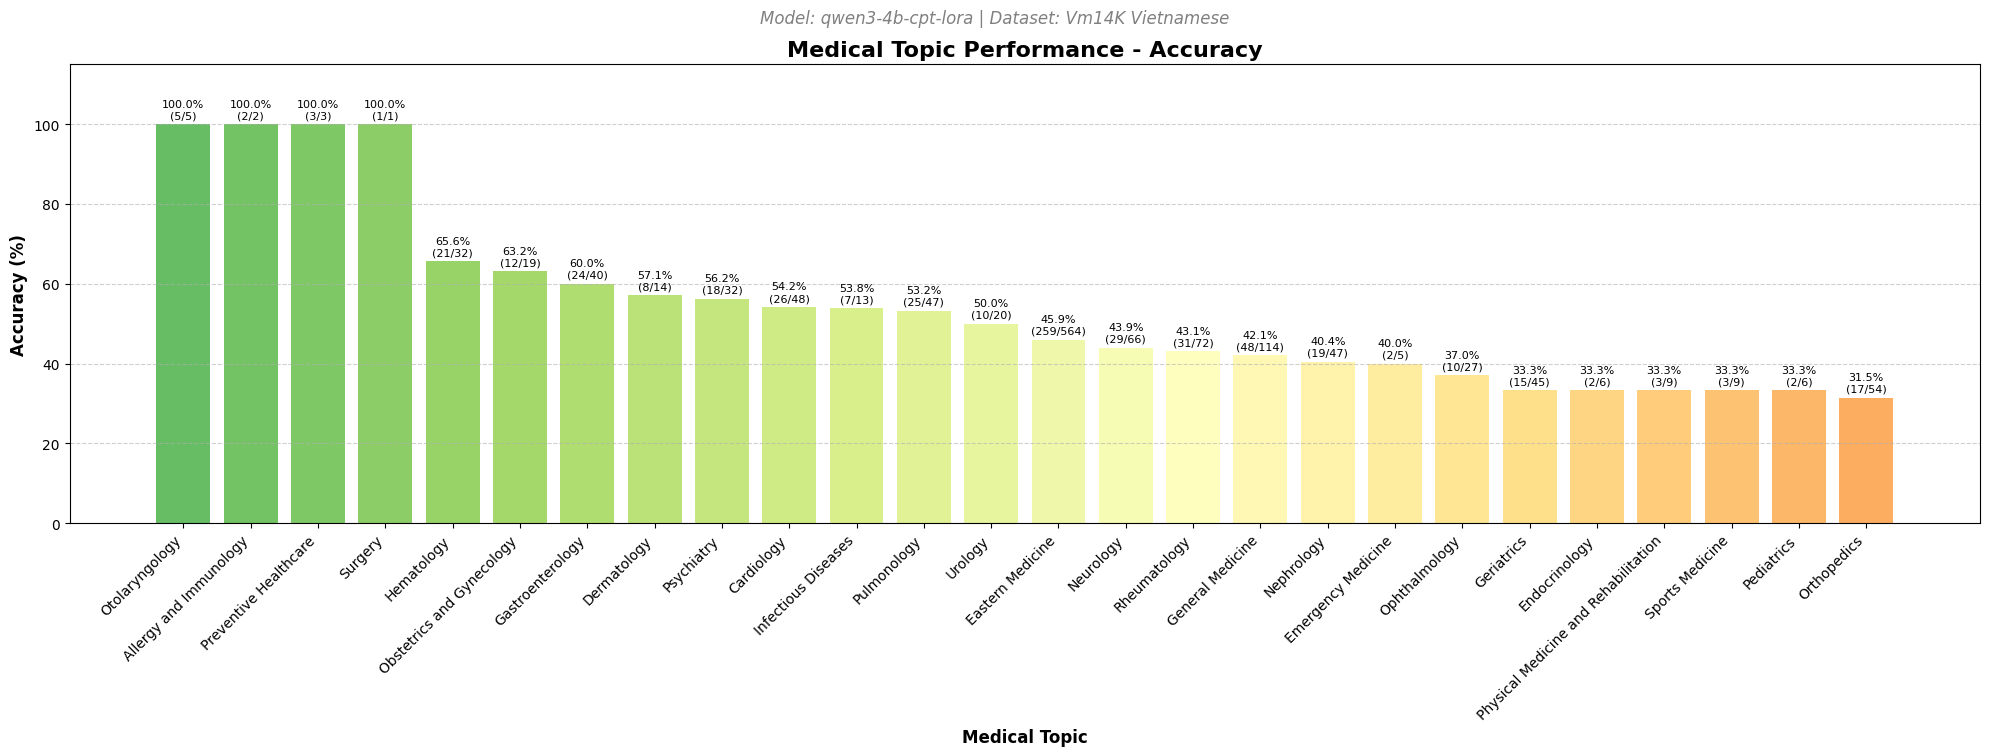

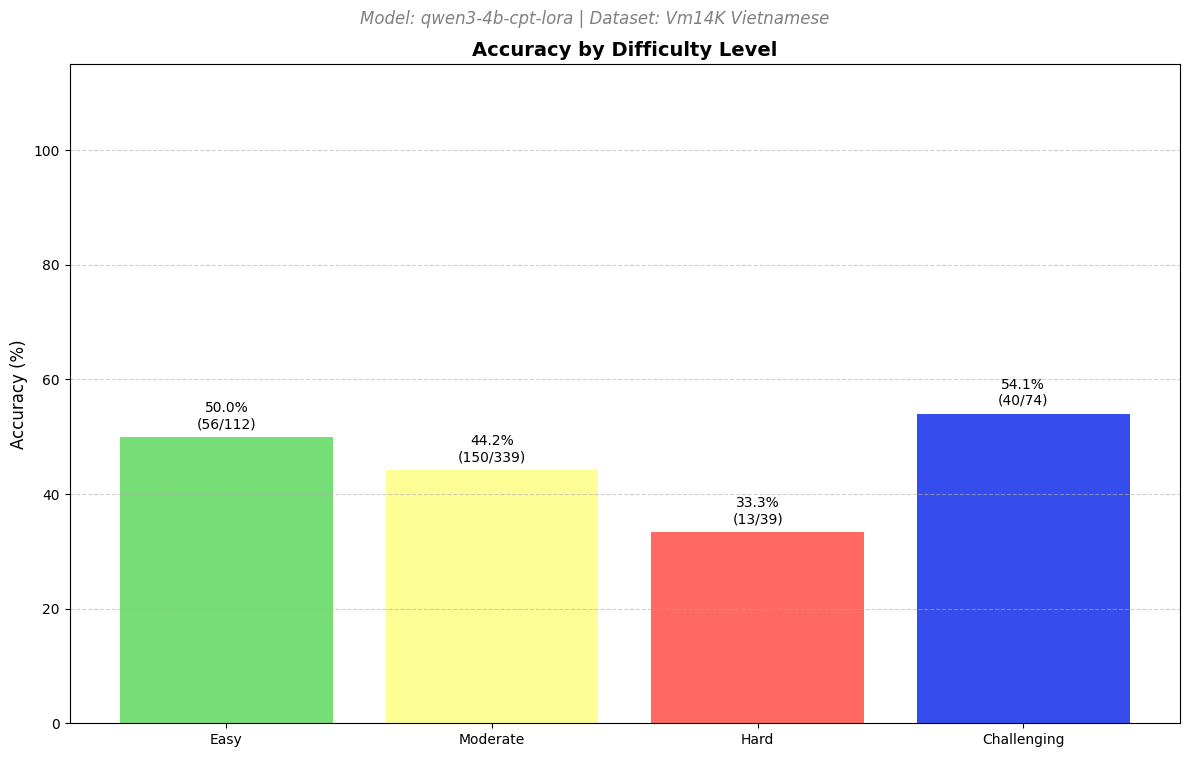

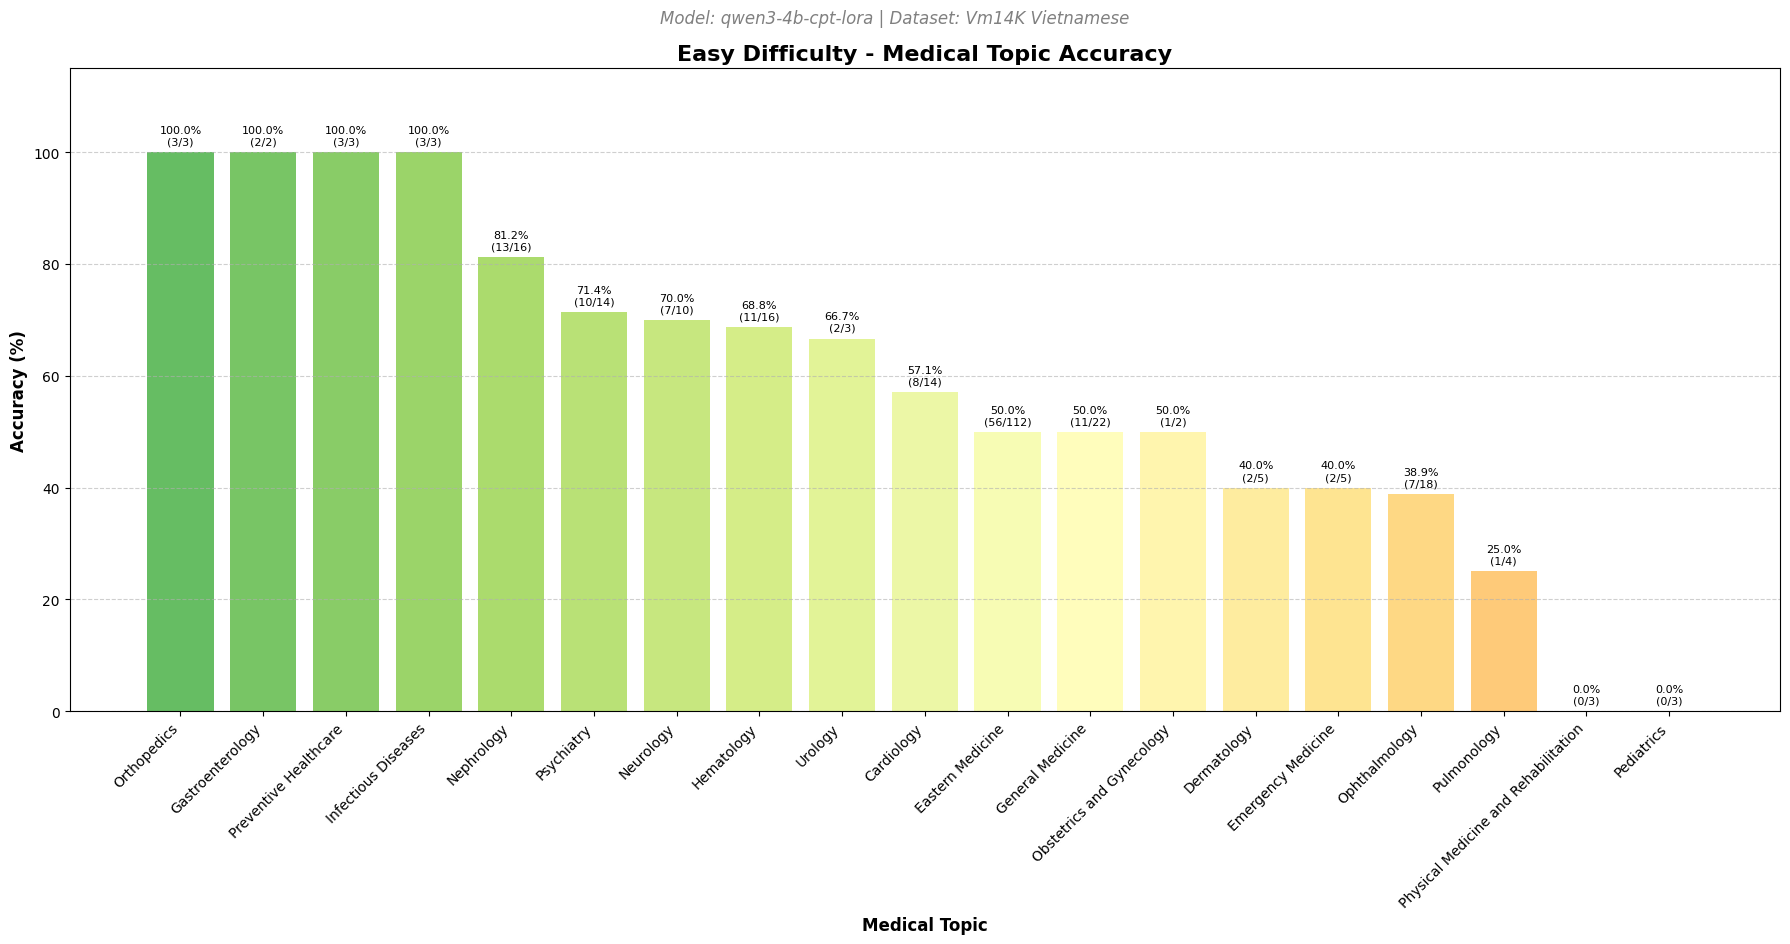

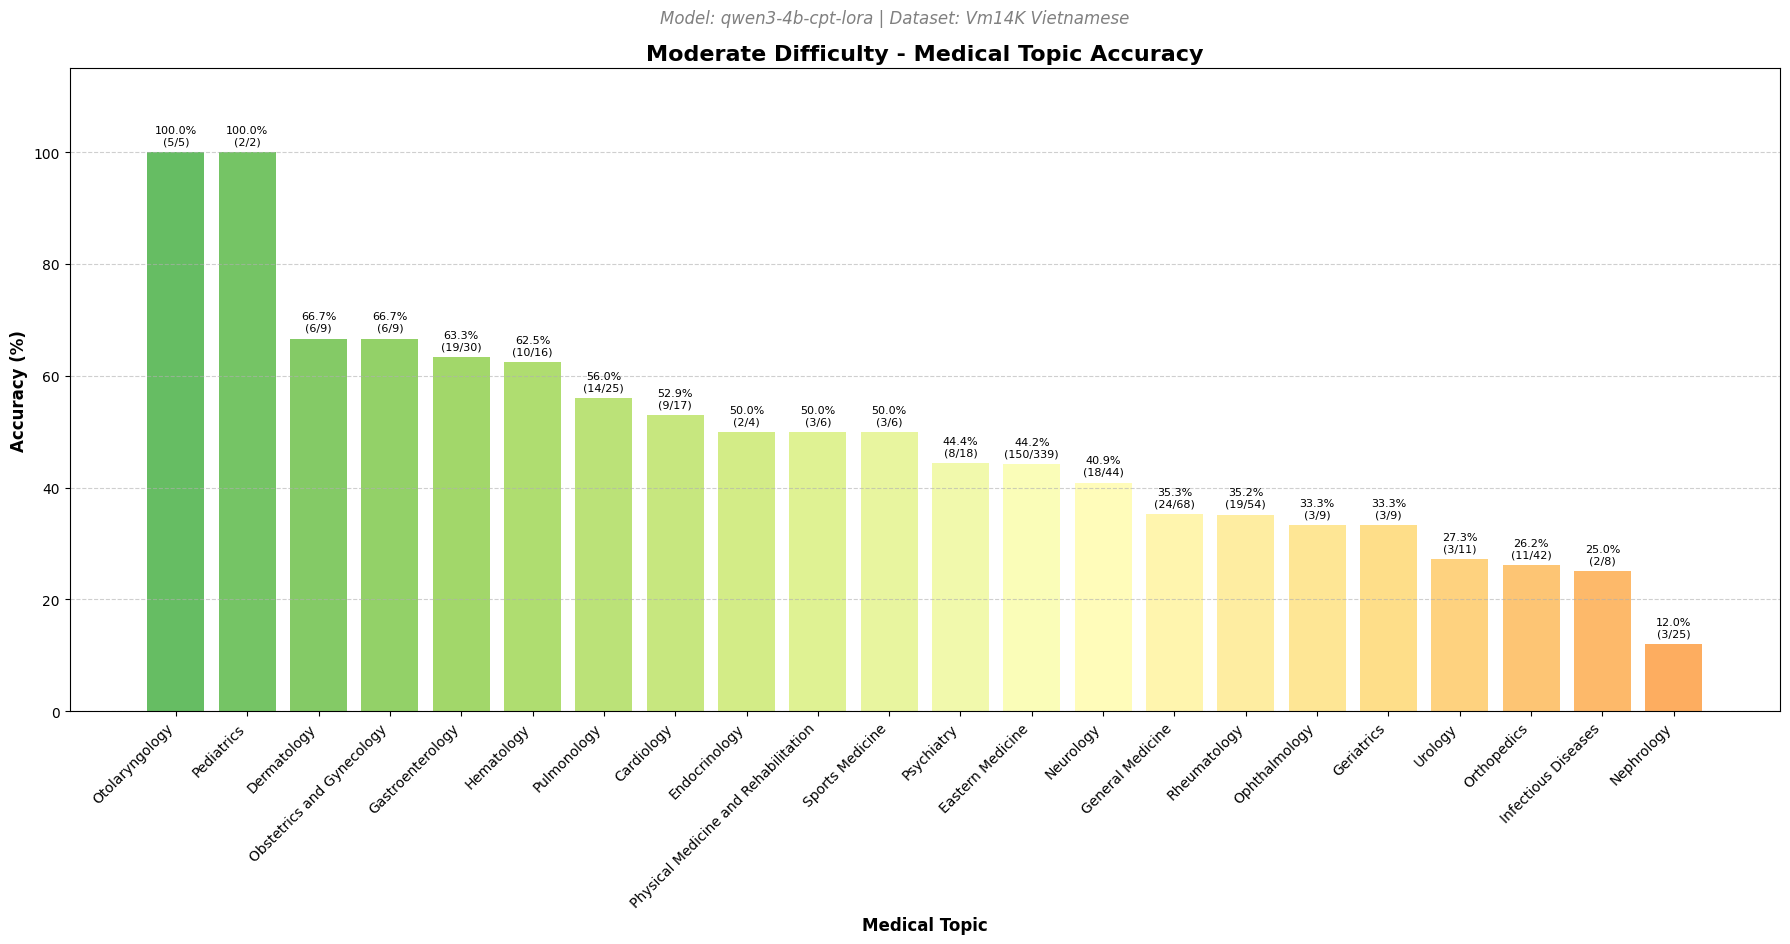

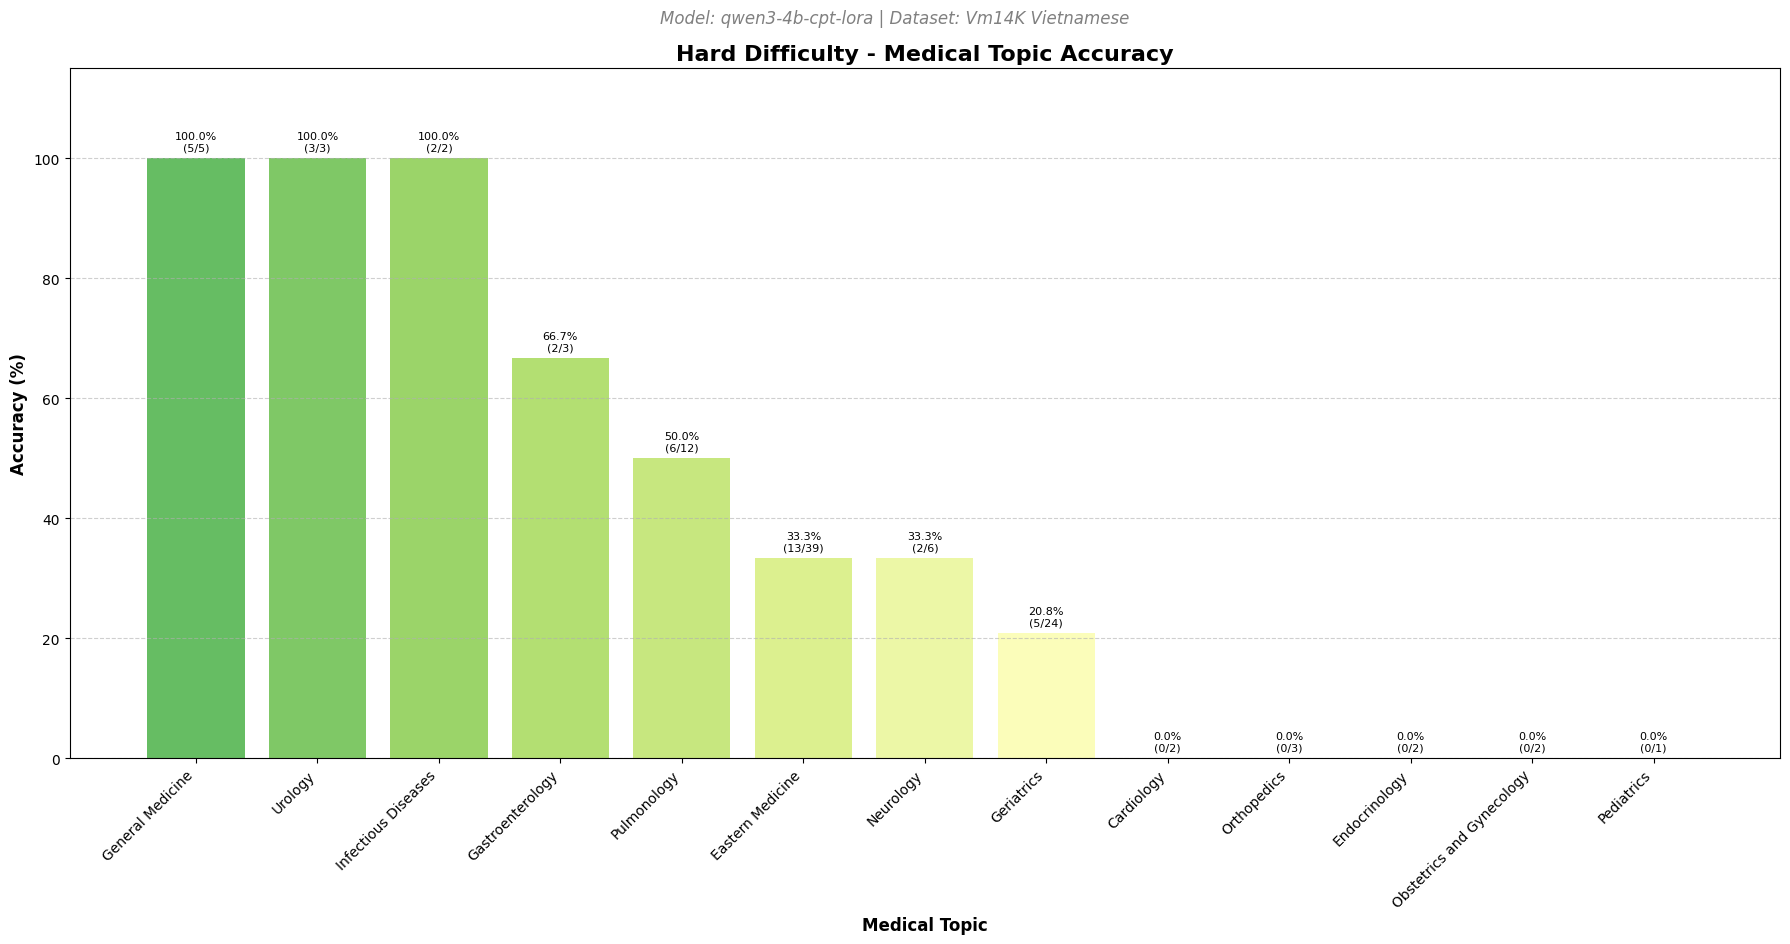

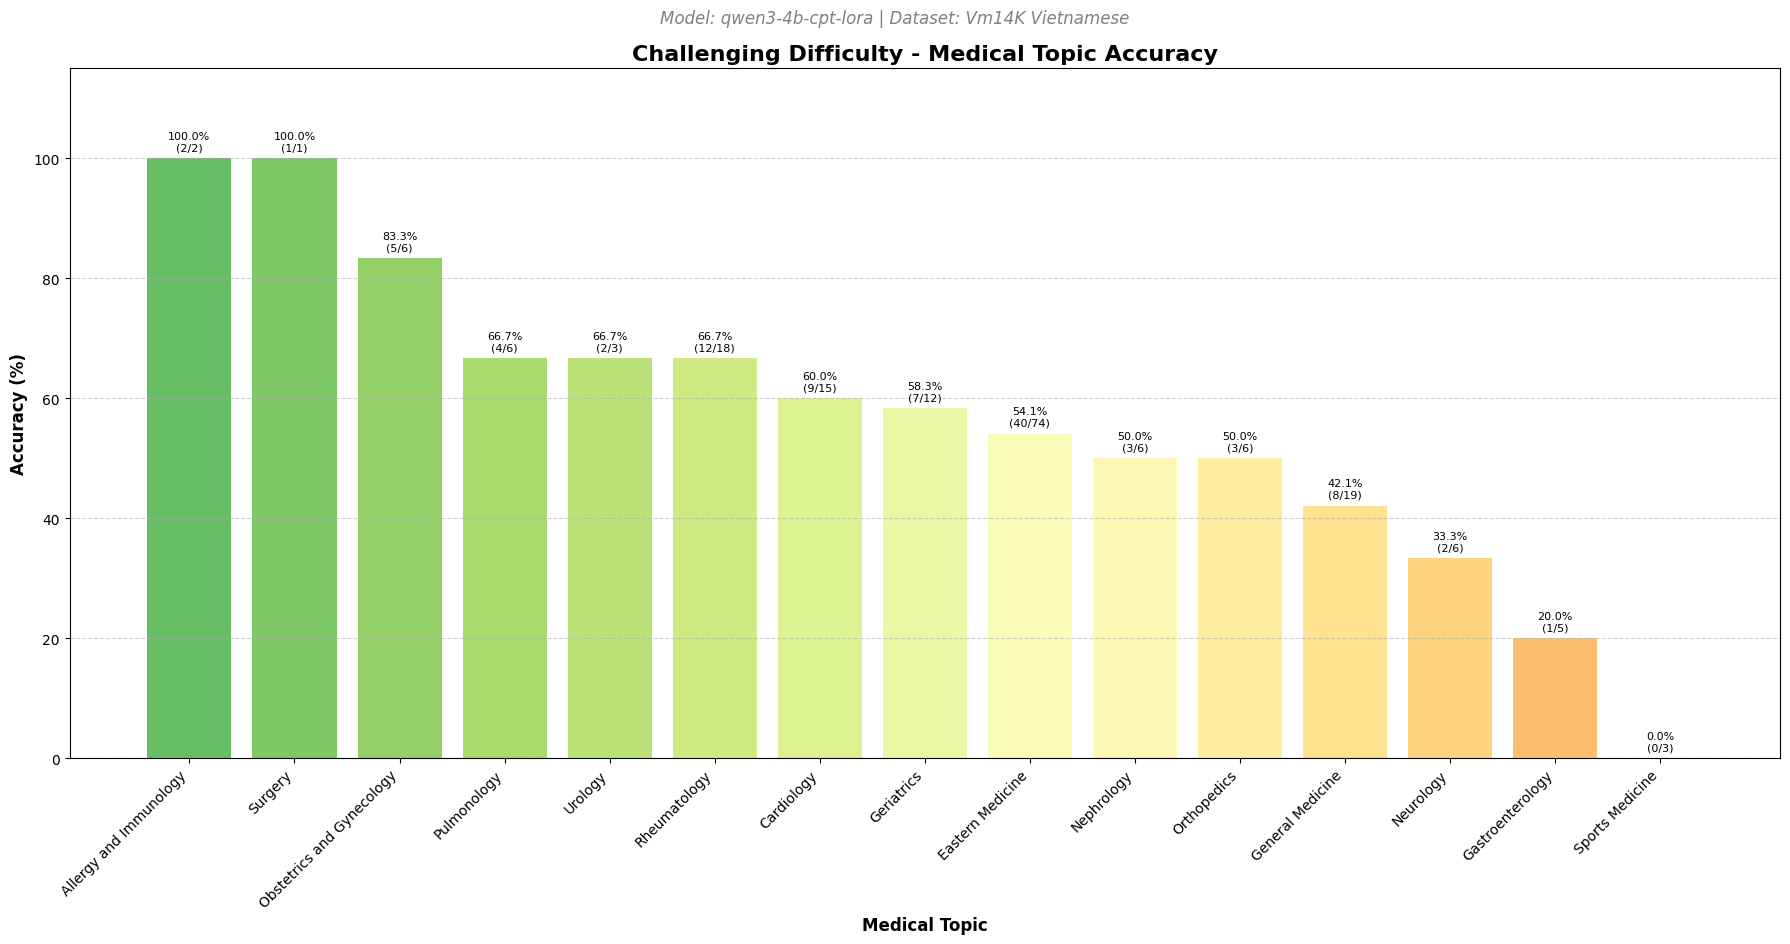

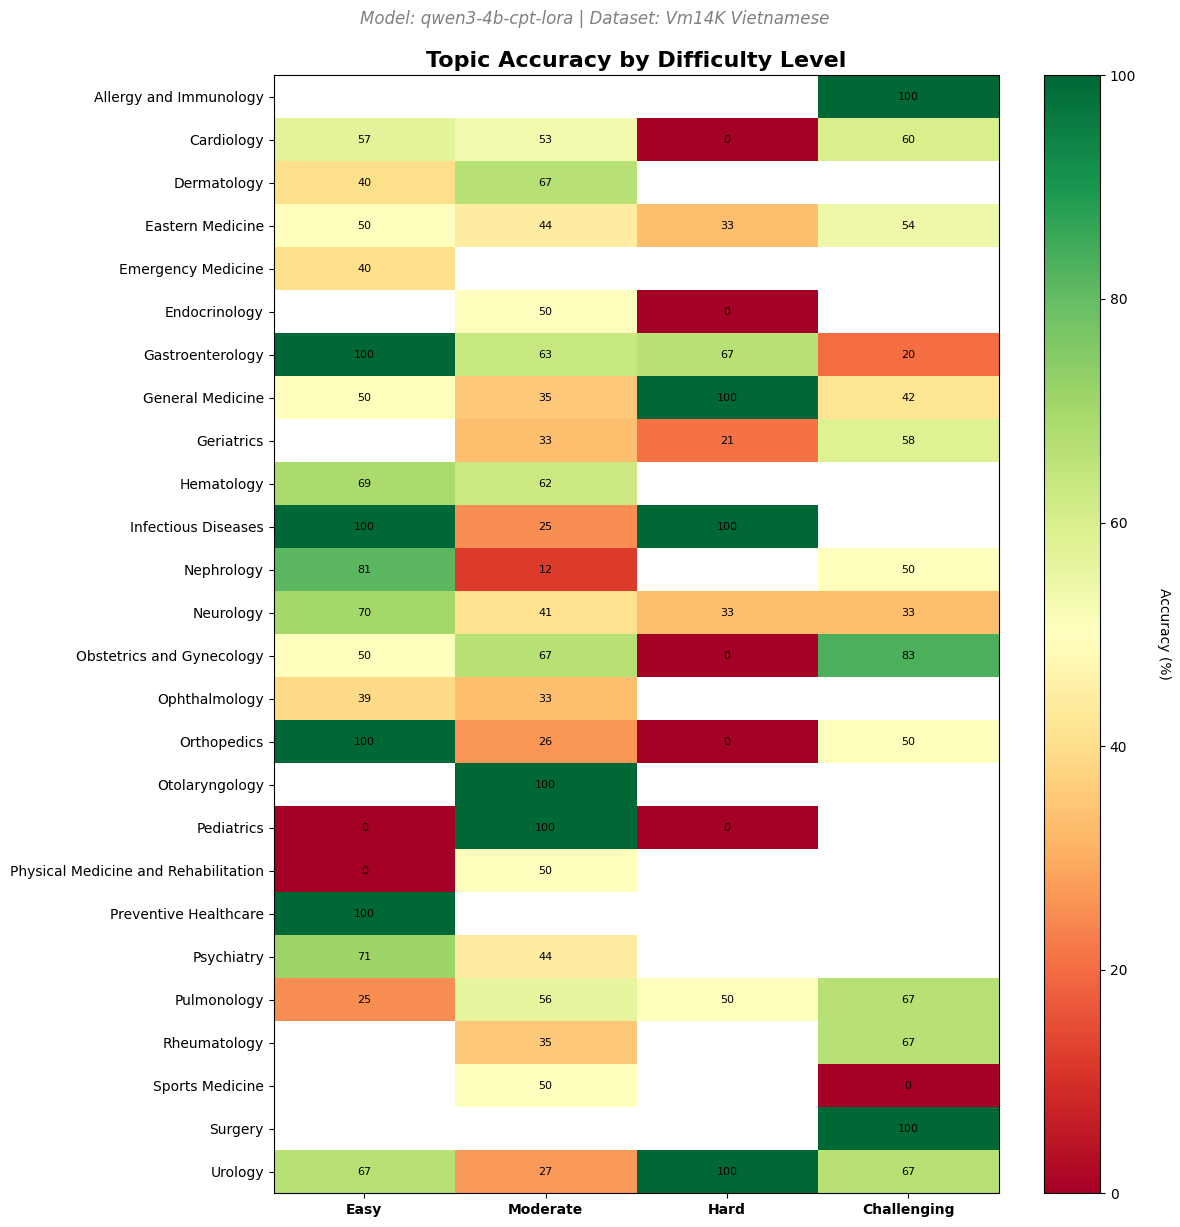

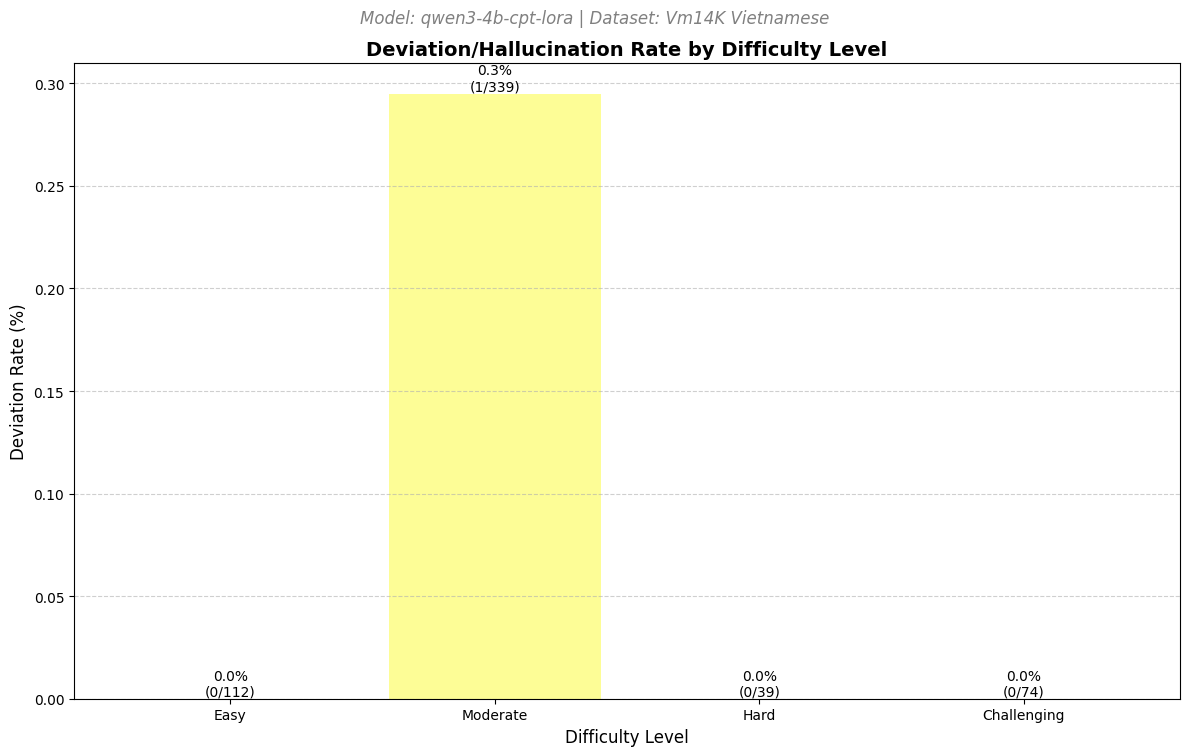

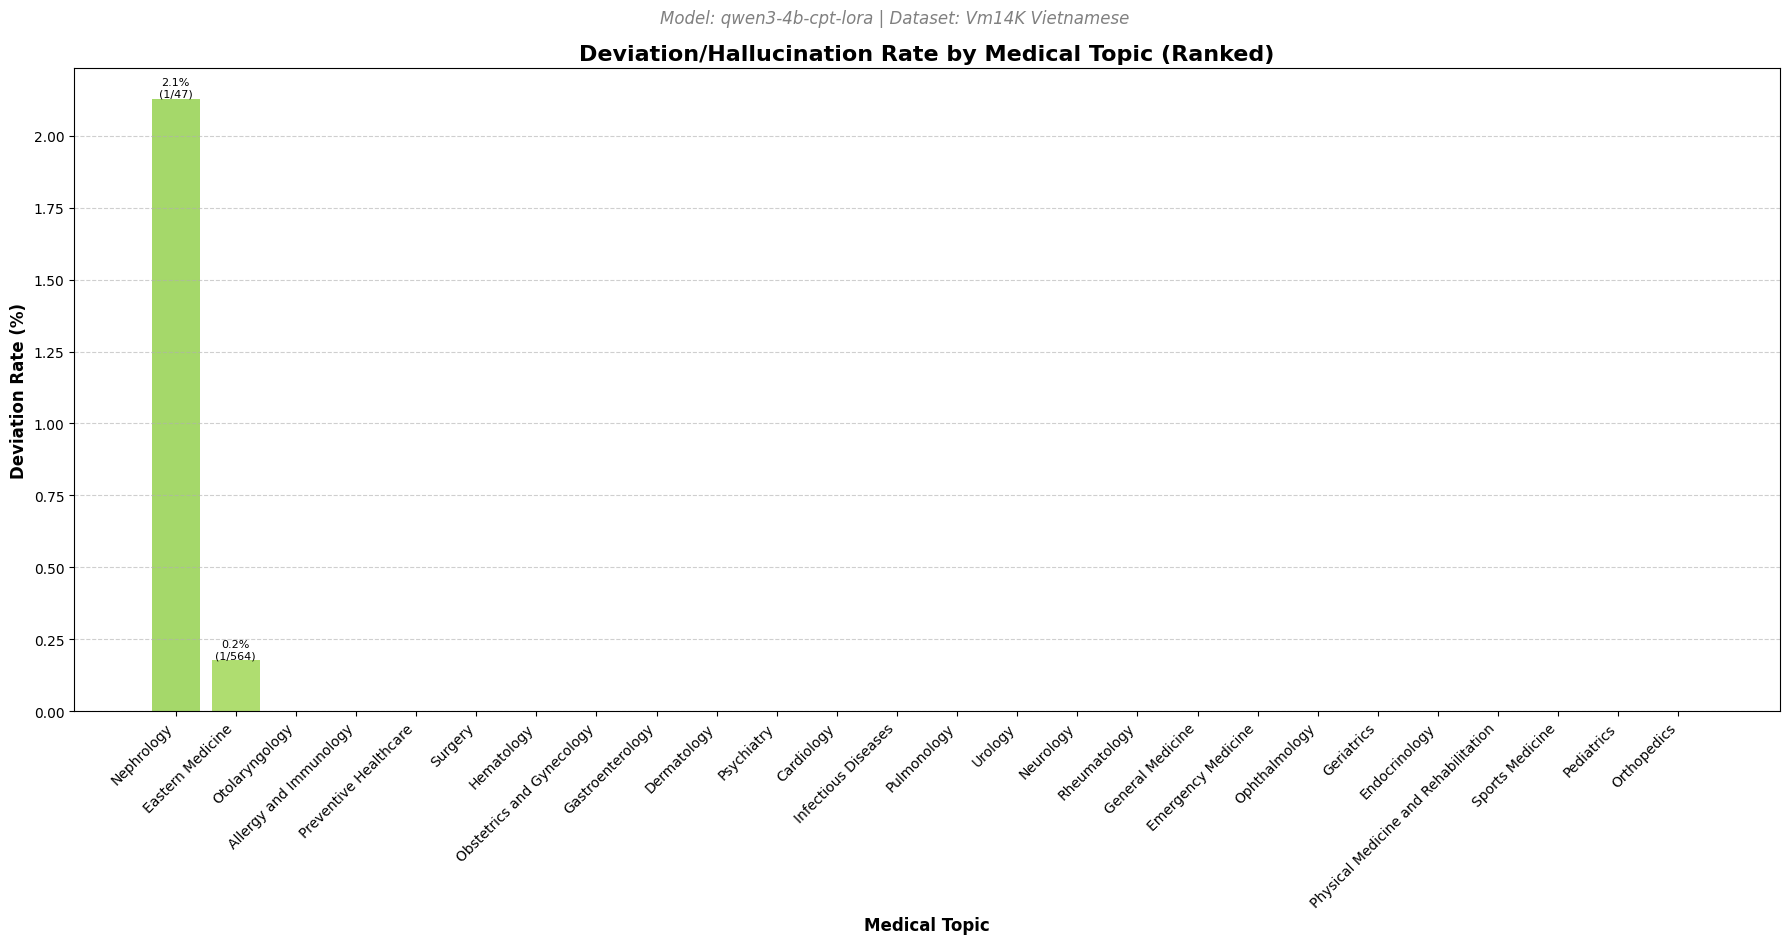

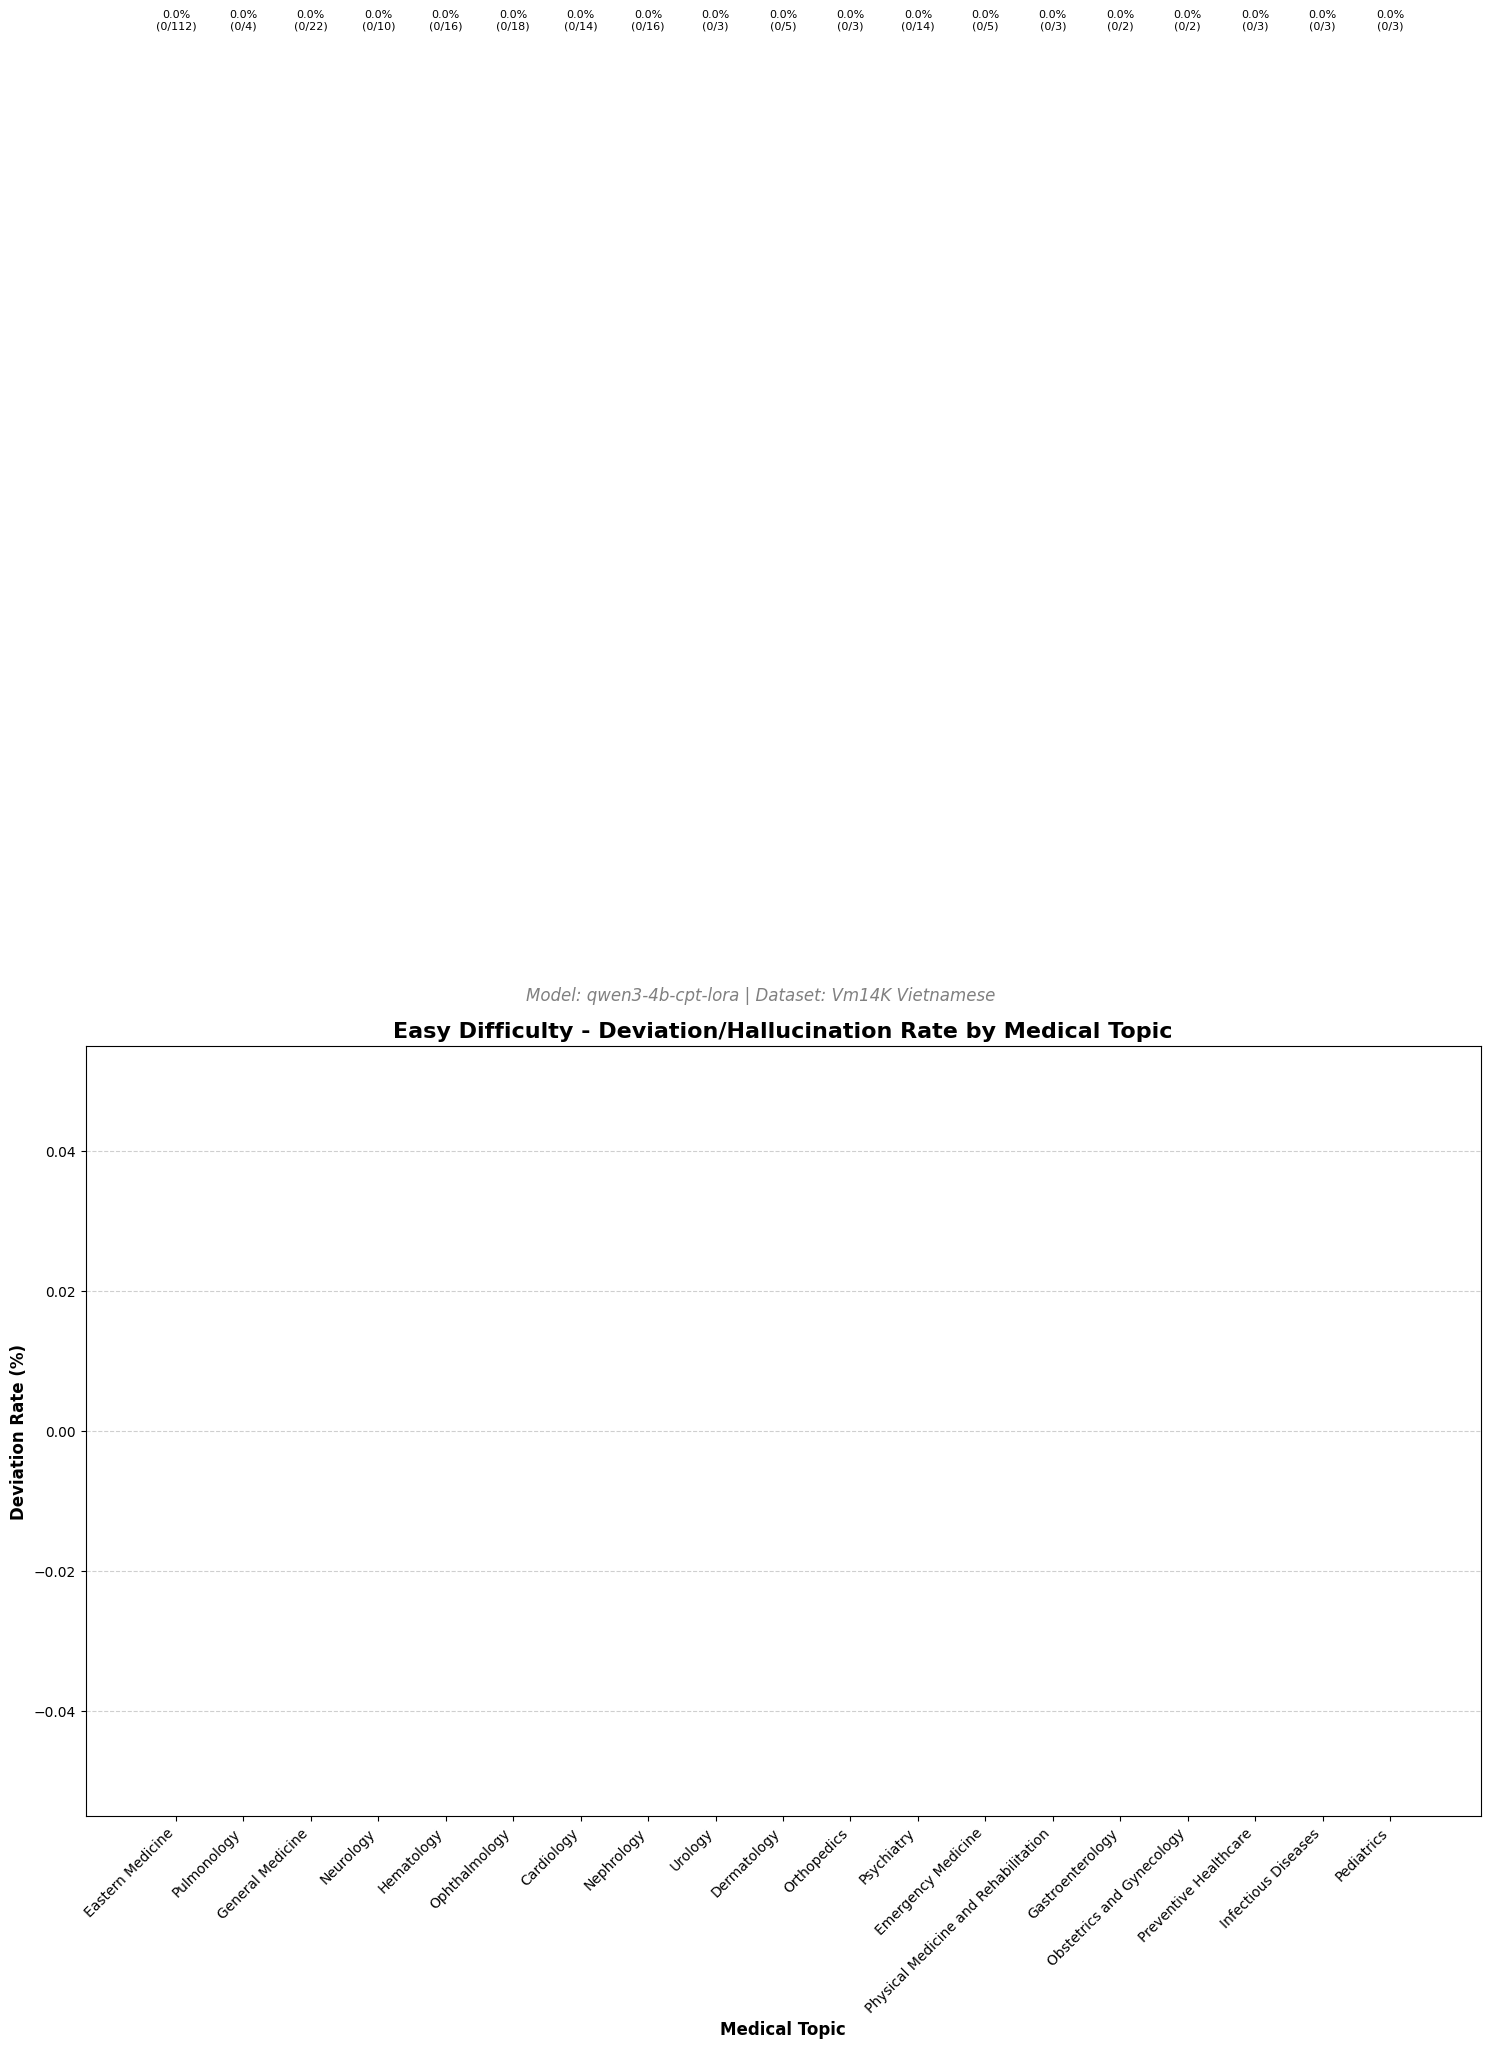

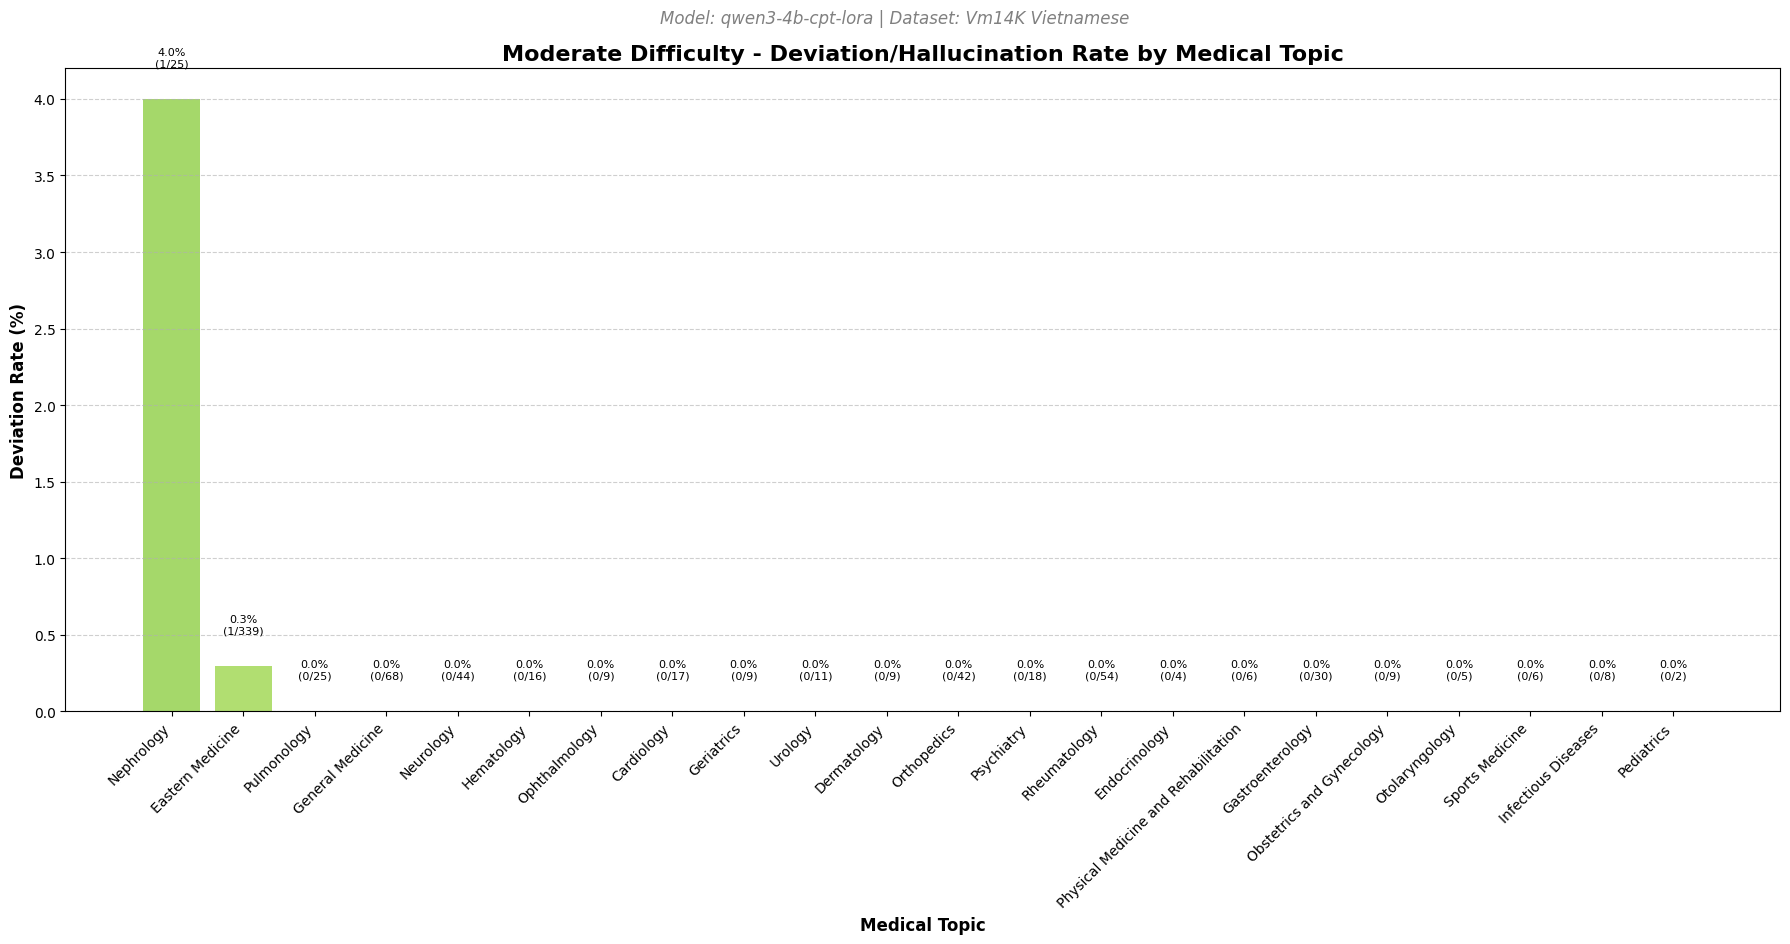

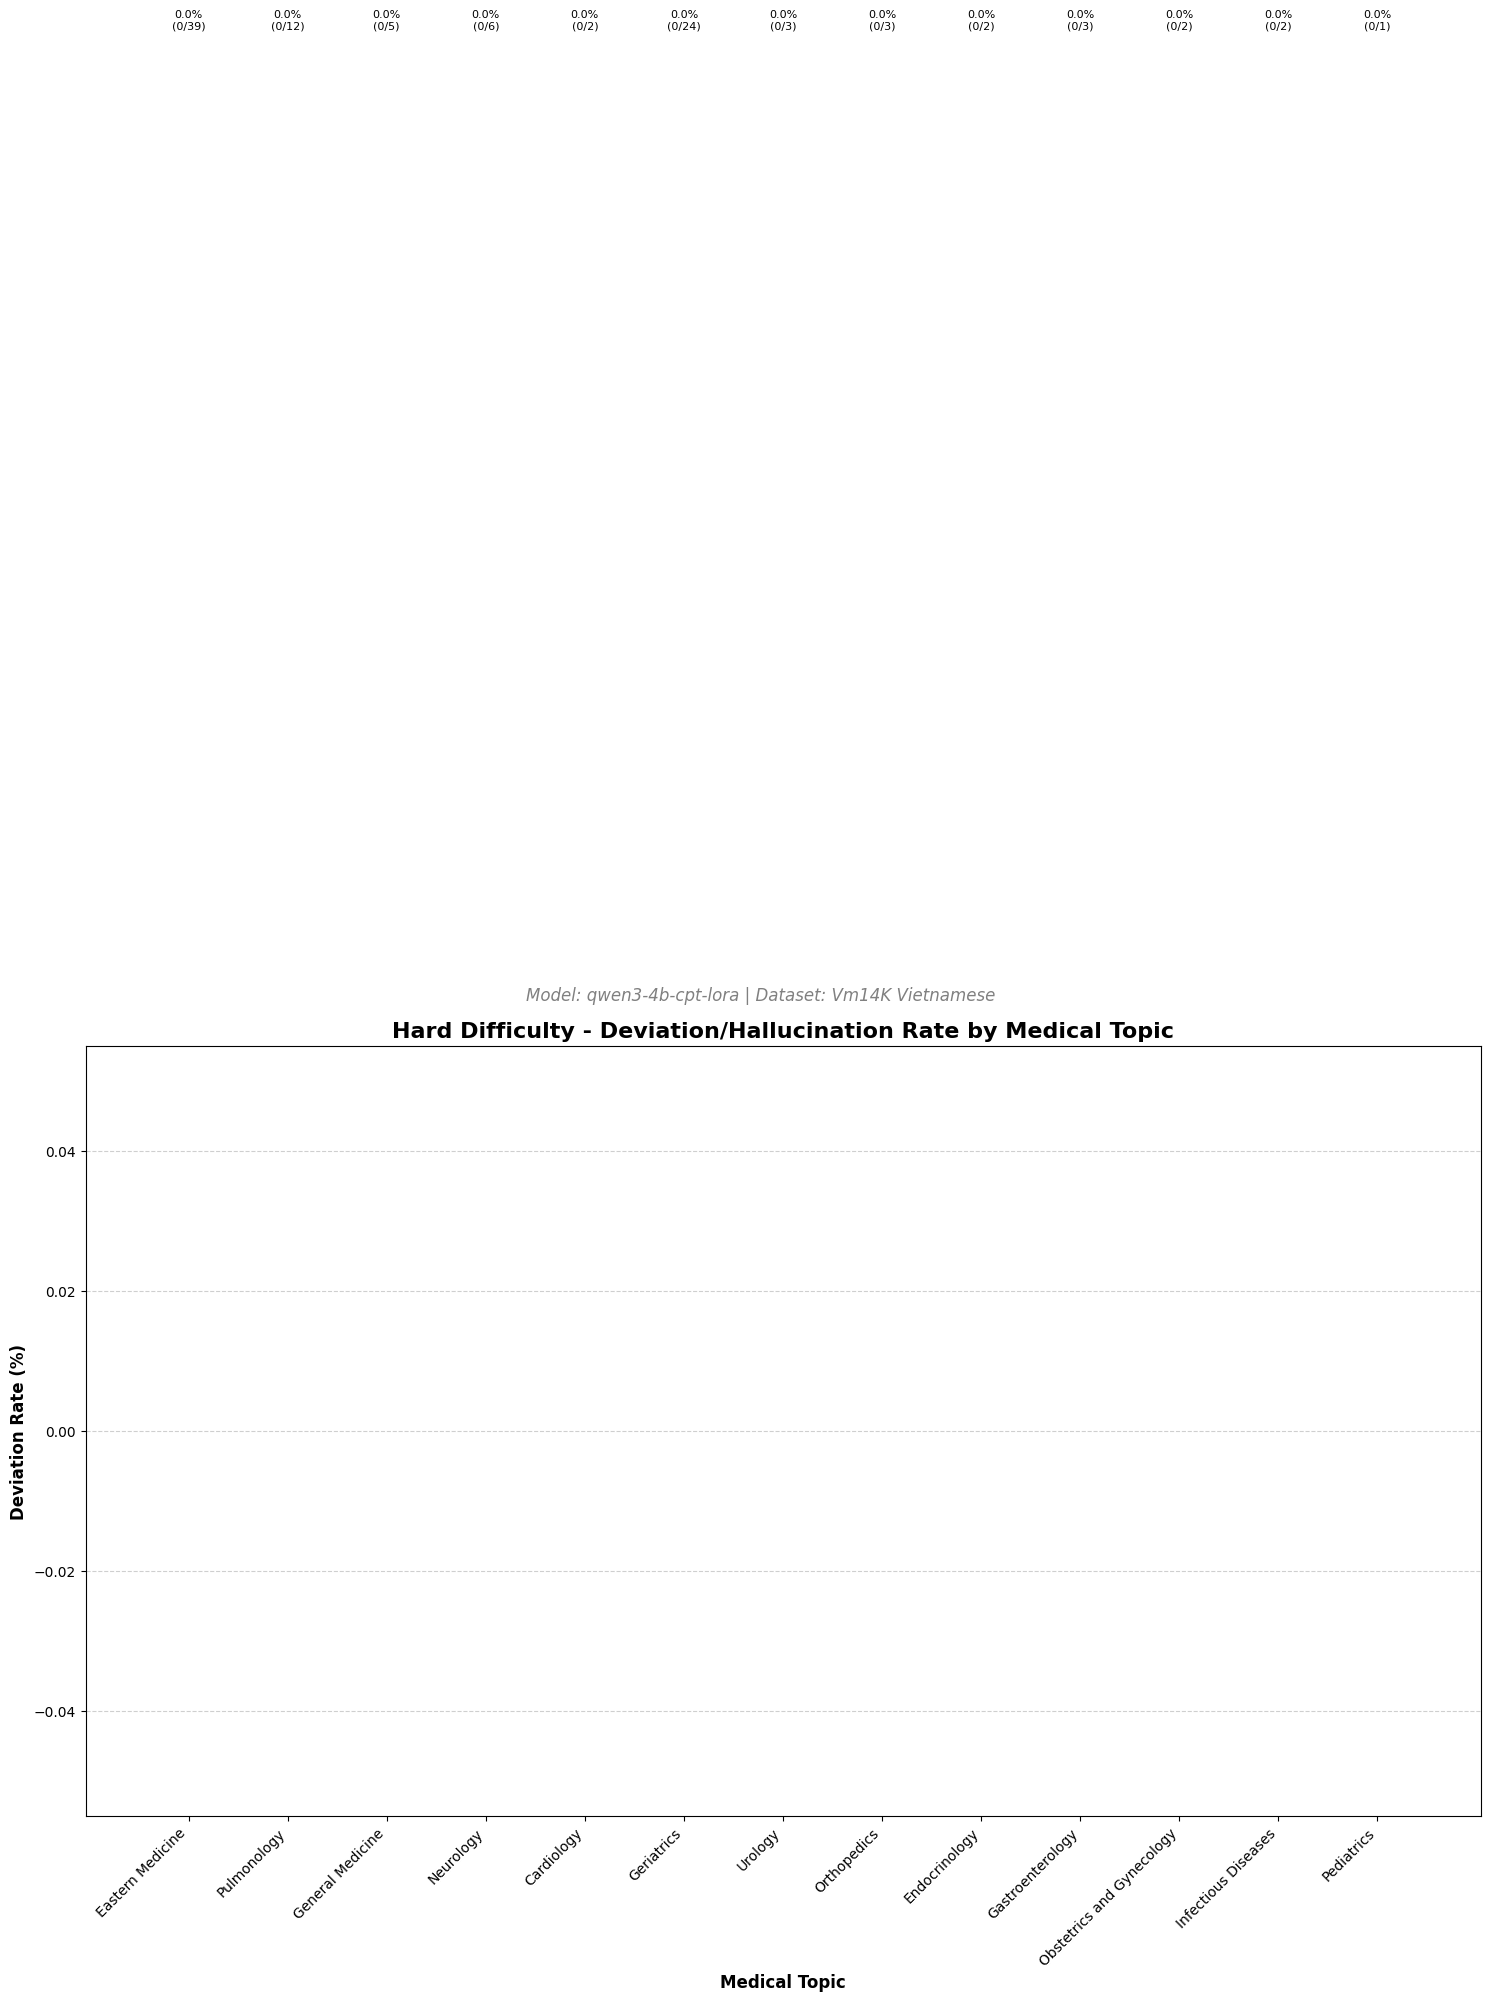

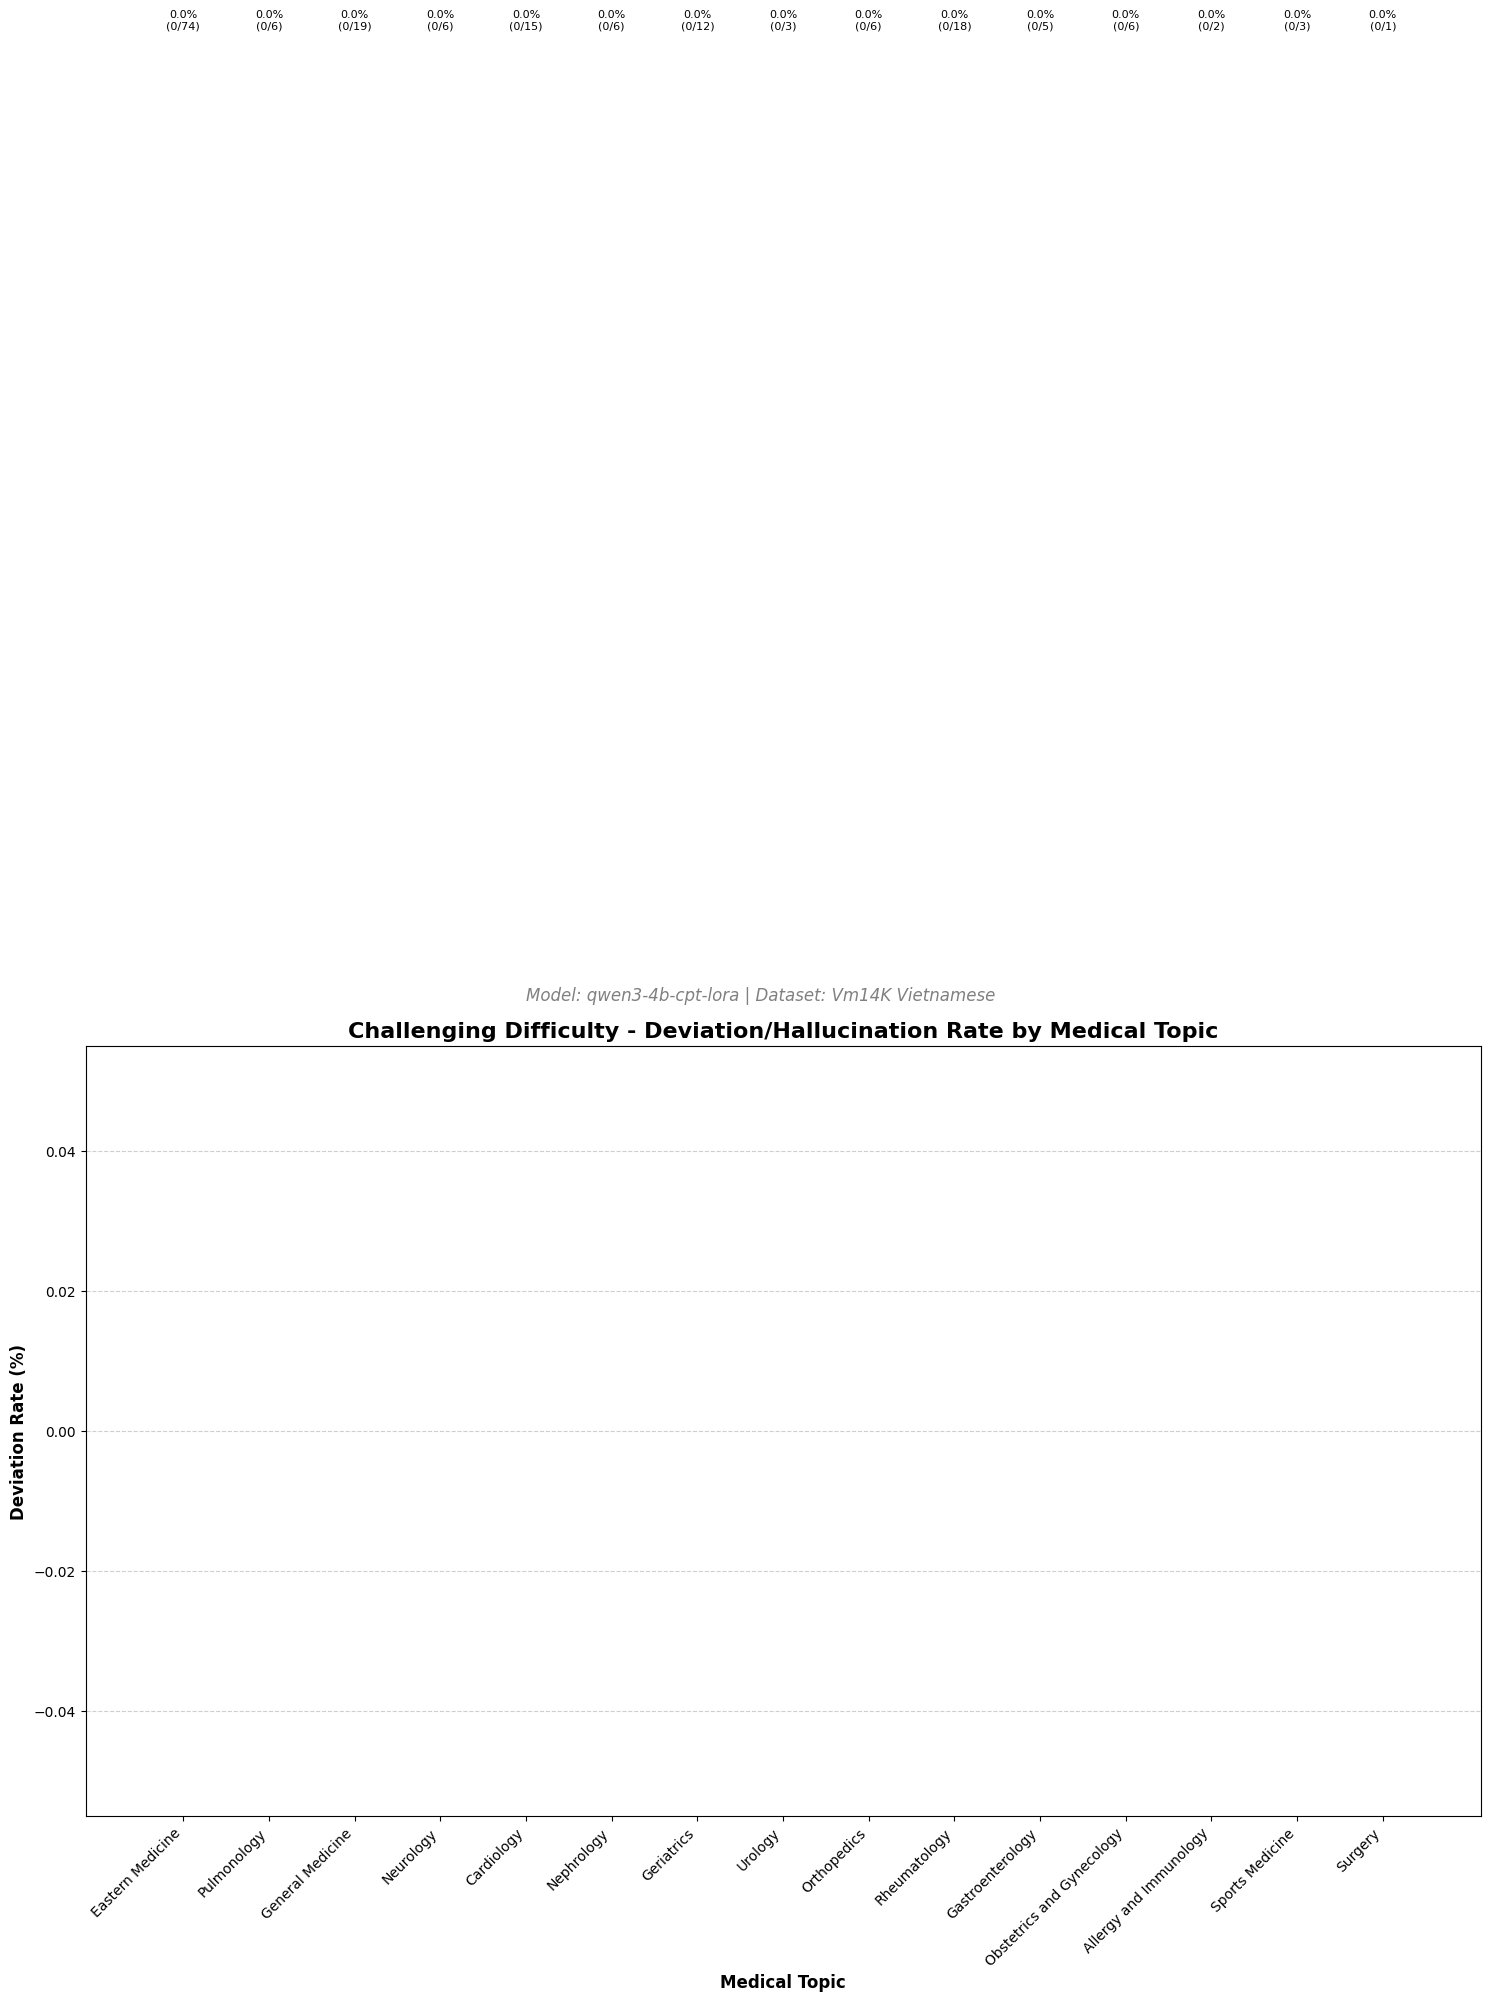

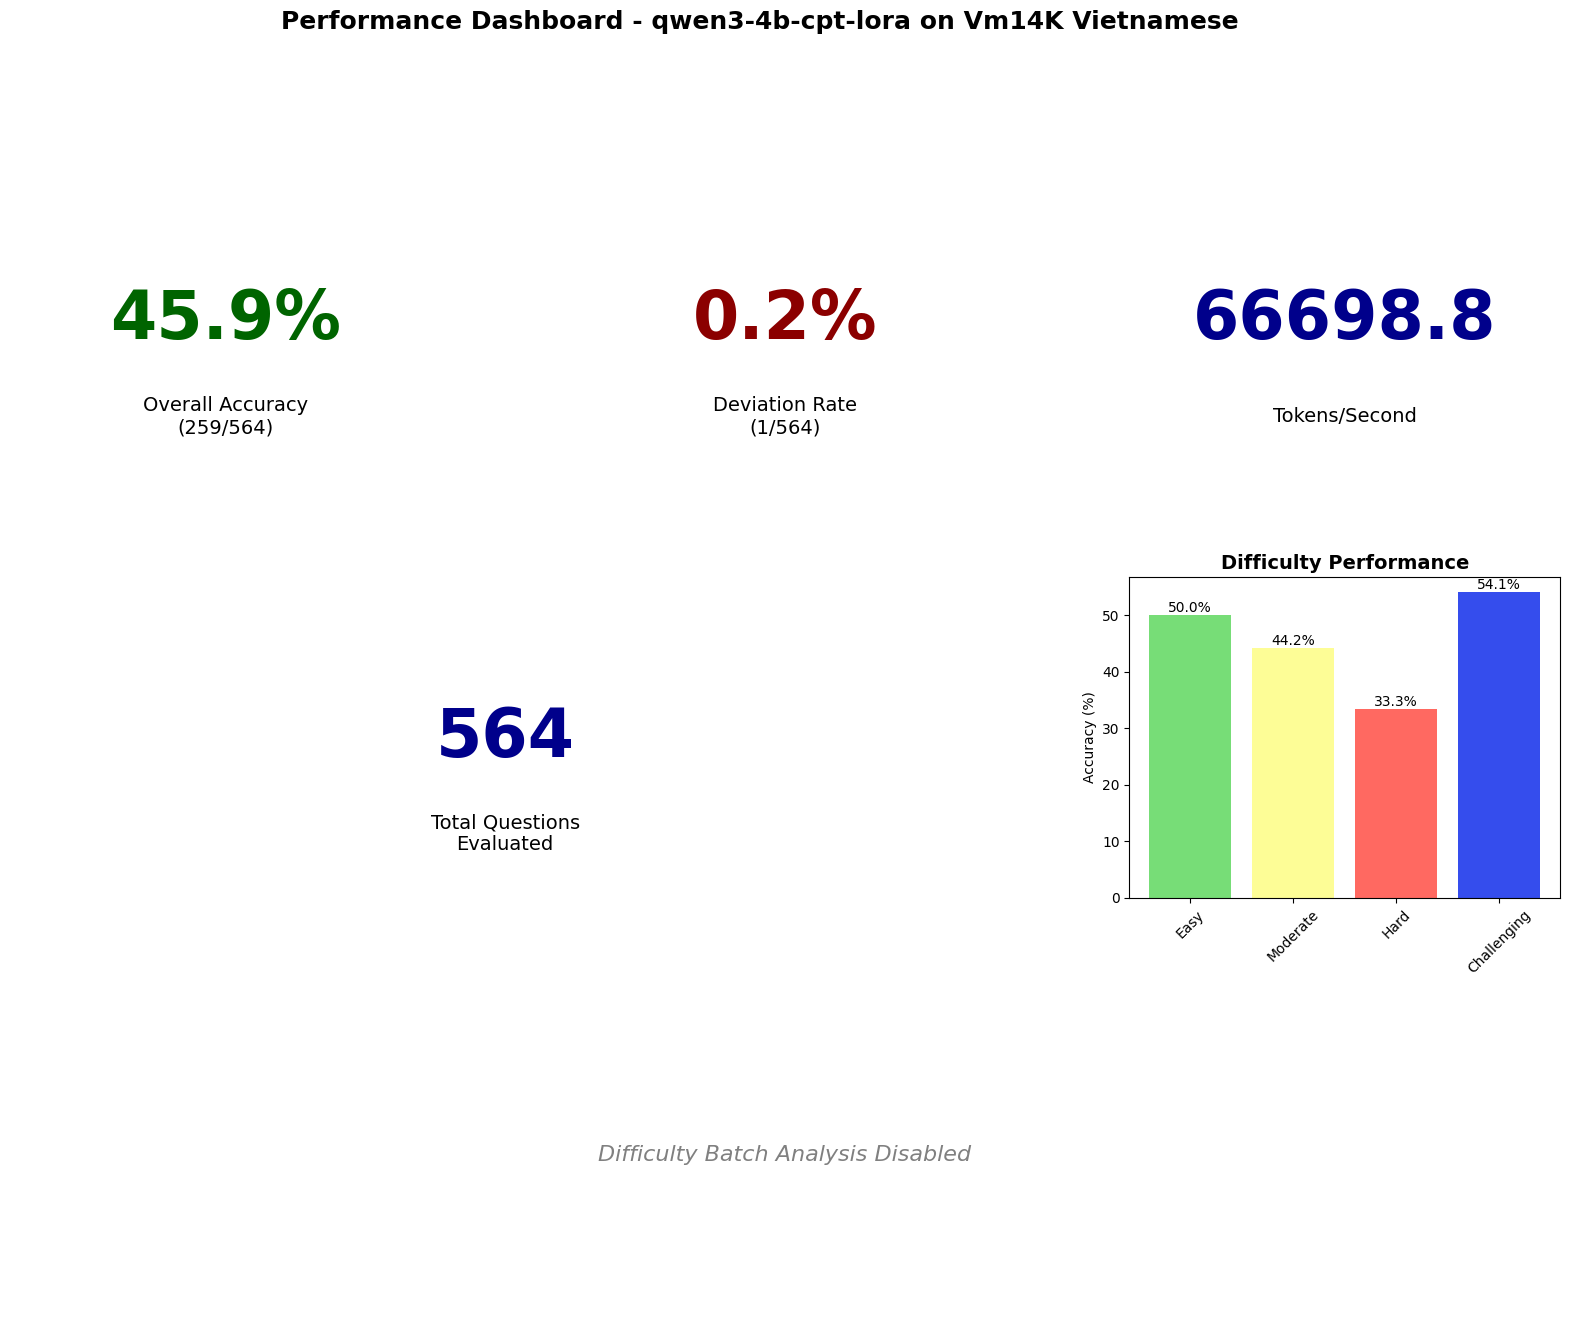

In [25]:
def create_bar_chart(topics, values, colors, title, xlabel, ylabel, rotation=45, ylim=None,
                    value_format='.1f', value_suffix='%', ax=None):
    """Helper function to create consistent bar charts"""
    if ax is None:
        fig, ax = plt.subplots(figsize=(18, 10))

    bars = ax.bar(range(len(topics)), values, color=colors)
    ax.set_xlabel(xlabel, fontsize=12, fontweight='bold')
    ax.set_ylabel(ylabel, fontsize=12, fontweight='bold')
    ax.set_title(title, fontsize=16, fontweight='bold')
    if ylim:
        ax.set_ylim(ylim)
    ax.set_xticks(range(len(topics)))
    ax.set_xticklabels(topics, rotation=rotation, ha='right')

    for bar in bars:
        height = bar.get_height()
        if height > 0:
            offset = 1 if value_suffix == '%' else 0.5
            ax.text(bar.get_x() + bar.get_width()/2., height + offset,
                   f'{height:{value_format}}{value_suffix}',
                   ha='center', va='bottom', fontsize=9)

    ax.grid(True, axis='y', linestyle='--', alpha=0.6)
    return bars

# Create display names for model and dataset
model_display_name = model_name.split('/')[-1] if '/' in model_name else model_name
dataset_display_name = dataset_name.replace('.jsonl', '').replace('_', ' ').title()

# 1. Topic Performance - Accuracy Chart
if topic_results:
    fig, ax1 = plt.subplots(1, 1, figsize=(20, 8))
    sorted_topic_results_for_plot = sorted(topic_results, key=lambda x: x['accuracy'], reverse=True)
    topics = [r['topic'] for r in sorted_topic_results_for_plot]
    accuracies = [r['accuracy'] for r in sorted_topic_results_for_plot]
    colors = plt.cm.RdYlGn(np.linspace(0.8, 0.3, len(topics)))

    bars = ax1.bar(range(len(topics)), accuracies, color=colors)
    ax1.set_xlabel('Medical Topic', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
    ax1.set_title('Medical Topic Performance - Accuracy', fontsize=16, fontweight='bold')
    fig.text(0.5, 0.94, f'Model: {model_display_name} | Dataset: {dataset_display_name}',
             ha='center', va='top', fontsize=12, style='italic', color='gray')
    ax1.set_ylim(0, 115)
    ax1.set_xticks(range(len(topics)))
    ax1.set_xticklabels(topics, rotation=45, ha='right')
    ax1.grid(True, axis='y', linestyle='--', alpha=0.6)

    for i, (bar, topic_data) in enumerate(zip(bars, sorted_topic_results_for_plot)):
        height = bar.get_height()
        if height > 0:
            ax1.text(bar.get_x() + bar.get_width()/2., height + 1,
                    f'{height:.1f}%\n({topic_data["correct"]}/{topic_data["total"]})',
                    ha='center', va='bottom', fontsize=8)

    plt.tight_layout(rect=[0, 0, 1, 0.92])
    plt.savefig(os.path.join(output_dir, "topic_performance_accuracy.png"), dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()

# 2. Difficulty Performance Chart
if difficulty_results:
    fig, ax = plt.subplots(figsize=(12, 8))
    difficulties = [r['difficulty'] for r in difficulty_results]
    diff_accuracies = [r['accuracy'] for r in difficulty_results]
    diff_colors = ['#77dd77', '#fdfd96', '#ff6961', '#1e39ece5'][:len(difficulties)]

    bars = ax.bar(difficulties, diff_accuracies, color=diff_colors)
    ax.set_title('Accuracy by Difficulty Level', fontsize=14, fontweight='bold')
    fig.text(0.5, 0.94, f'Model: {model_display_name} | Dataset: {dataset_display_name}',
             ha='center', va='top', fontsize=12, style='italic', color='gray')
    ax.set_ylabel('Accuracy (%)', fontsize=12)
    ax.set_ylim(0, 115)
    ax.grid(True, axis='y', linestyle='--', alpha=0.6)

    for bar, result in zip(bars, difficulty_results):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 1,
               f'{height:.1f}%\n({result["correct"]}/{result["total"]})',
               ha='center', va='bottom', fontsize=10)

    plt.tight_layout(rect=[0, 0, 1, 0.92])
    plt.savefig(os.path.join(output_dir, "difficulty_performance.png"), dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()

# 3. Batch Token Speed vs Accuracy (if batch analysis enabled)
if 'topic_tps_results' in locals() and topic_tps_results and topic_results and ENABLE_TOPIC_BATCH_ANALYSIS:
    fig, ax = plt.subplots(figsize=(14, 10))

    topic_accuracy_dict = {r['topic']: r['accuracy'] for r in topic_results}
    token_speeds = []
    accuracies_for_tokens = []
    topic_labels = []

    for topic, token_stats in topic_tps_results.items():
        if topic in topic_accuracy_dict:
            token_speeds.append(token_stats['batch_tokens_per_second'])
            accuracies_for_tokens.append(topic_accuracy_dict[topic])
            topic_labels.append(topic)

    if token_speeds and accuracies_for_tokens:
        scatter = ax.scatter(token_speeds, accuracies_for_tokens,
                           c=range(len(topic_labels)), cmap='coolwarm',
                           s=100, alpha=0.7, edgecolors='black')

        for i, topic in enumerate(topic_labels):
            ax.annotate(topic, (token_speeds[i], accuracies_for_tokens[i]),
                       xytext=(5, 5), textcoords='offset points', fontsize=8)

        ax.set_xlabel('Batch Tokens/Second', fontsize=12, fontweight='bold')
        ax.set_ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
        ax.set_title('Batch Token Speed vs Accuracy by Medical Topic', fontsize=16, fontweight='bold')
        fig.text(0.5, 0.94, f'Model: {model_display_name} | Dataset: {dataset_display_name}',
                 ha='center', va='top', fontsize=12, style='italic', color='gray')
        ax.grid(True, linestyle='--', alpha=0.6)

        if len(token_speeds) > 1:
            correlation = np.corrcoef(token_speeds, accuracies_for_tokens)[0, 1]
            ax.text(0.05, 0.95, f'Correlation: {correlation:.3f}',
                   transform=ax.transAxes, fontsize=12,
                   bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

        plt.tight_layout(rect=[0, 0, 1, 0.92])
        plt.savefig(os.path.join(output_dir, "batch_token_speed_vs_accuracy.png"), dpi=300, bbox_inches='tight')
        plt.show()
        plt.close()

# 4. Topic-Difficulty Performance Charts
if topic_difficulty_performance:
    for difficulty in difficulty_order:
        difficulty_topics = []
        for topic in topic_difficulty_performance.keys():
            if difficulty in topic_difficulty_performance[topic]:
                data = topic_difficulty_performance[topic][difficulty]
                total = data['correct'] + data['incorrect']
                if total > 0:
                    accuracy = (data['correct'] / total) * 100
                    difficulty_topics.append({
                        'topic': topic, 'accuracy': accuracy, 'correct': data['correct'],
                        'total': total
                    })
        if not difficulty_topics:
            continue

        difficulty_topics_by_accuracy = sorted(difficulty_topics, key=lambda x: x['accuracy'], reverse=True)
        fig, ax = plt.subplots(figsize=(18, 10))
        topics = [d['topic'] for d in difficulty_topics_by_accuracy]
        accuracies = [d['accuracy'] for d in difficulty_topics_by_accuracy]
        ratios = [f"{d['correct']}/{d['total']}" for d in difficulty_topics_by_accuracy]
        colors = plt.cm.RdYlGn(np.linspace(0.8, 0.3, len(topics)))
        bars = ax.bar(range(len(topics)), accuracies, color=colors)

        ax.set_xlabel('Medical Topic', fontsize=12, fontweight='bold')
        ax.set_ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
        ax.set_title(f'{difficulty} Difficulty - Medical Topic Accuracy', fontsize=16, fontweight='bold')
        fig.text(0.5, 0.94, f'Model: {model_display_name} | Dataset: {dataset_display_name}',
                 ha='center', va='top', fontsize=12, style='italic', color='gray')
        ax.set_ylim(0, 115)
        ax.set_xticks(range(len(topics)))
        ax.set_xticklabels(topics, rotation=45, ha='right')

        for i, (bar, ratio) in enumerate(zip(bars, ratios)):
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height + 1,
                    f'{height:.1f}%\n({ratio})', ha='center', va='bottom', fontsize=8)

        ax.grid(True, axis='y', linestyle='--', alpha=0.6)
        plt.tight_layout(rect=[0, 0, 1, 0.92])
        plt.savefig(os.path.join(output_dir, f"{difficulty.lower()}_topics_accuracy.png"), dpi=300, bbox_inches='tight')
        plt.show()
        plt.close()

# 5. Accuracy Heatmap
if topic_difficulty_performance:
    heatmap_topics = sorted(topic_difficulty_performance.keys())
    heatmap_difficulties = ['Easy', 'Moderate', 'Hard', 'Challenging']
    accuracy_matrix = []

    for topic in heatmap_topics:
        row = []
        for difficulty in heatmap_difficulties:
            data = topic_difficulty_performance.get(topic, {}).get(difficulty)
            if data and (data['correct'] + data['incorrect']) > 0:
                row.append((data['correct'] / (data['correct'] + data['incorrect'])) * 100)
            else:
                row.append(np.nan)
        accuracy_matrix.append(row)

    if accuracy_matrix and any(any(not np.isnan(cell) for cell in row) for row in accuracy_matrix):
        fig, ax = plt.subplots(figsize=(12, max(10, len(heatmap_topics) * 0.5)))
        im = ax.imshow(np.array(accuracy_matrix), cmap='RdYlGn', aspect='auto', vmin=0, vmax=100)
        ax.set_xticks(np.arange(len(heatmap_difficulties)))
        ax.set_yticks(np.arange(len(heatmap_topics)))
        ax.set_xticklabels(heatmap_difficulties, fontweight='bold')
        ax.set_yticklabels(heatmap_topics)
        cbar = plt.colorbar(im, ax=ax)
        cbar.set_label('Accuracy (%)', rotation=-90, va="bottom", labelpad=15)

        for i in range(len(heatmap_topics)):
            for j in range(len(heatmap_difficulties)):
                if not np.isnan(accuracy_matrix[i][j]):
                    ax.text(j, i, f'{accuracy_matrix[i][j]:.0f}',
                           ha="center", va="center", color="black", fontsize=8)

        ax.set_title('Topic Accuracy by Difficulty Level', fontsize=16, fontweight='bold')
        fig.text(0.5, 0.94, f'Model: {model_display_name} | Dataset: {dataset_display_name}',
                 ha='center', va='top', fontsize=12, style='italic', color='gray')
        plt.tight_layout(rect=[0, 0, 1, 0.92])
        plt.savefig(os.path.join(output_dir, "topic_difficulty_accuracy_heatmap.png"), dpi=300, bbox_inches='tight')
        plt.show()
        plt.close()

# 6. Deviation Rate by Difficulty
if difficulty_results:
    fig, ax = plt.subplots(figsize=(12, 8))

    difficulties = [r['difficulty'] for r in difficulty_results]
    deviation_rates = []
    deviation_counts = []

    for result in difficulty_results:
        deviation_rate = (result['deviations'] / result['total']) * 100 if result['total'] > 0 else 0
        deviation_rates.append(deviation_rate)
        deviation_counts.append(result['deviations'])

    diff_colors = ['#77dd77', '#fdfd96', '#ff6961', '#1e39ece5'][:len(difficulties)]
    bars = ax.bar(difficulties, deviation_rates, color=diff_colors)
    ax.set_title('Deviation/Hallucination Rate by Difficulty Level', fontsize=14, fontweight='bold')
    fig.text(0.5, 0.94, f'Model: {model_display_name} | Dataset: {dataset_display_name}',
             ha='center', va='top', fontsize=12, style='italic', color='gray')
    ax.set_ylabel('Deviation Rate (%)', fontsize=12)
    ax.set_xlabel('Difficulty Level', fontsize=12)
    ax.grid(True, axis='y', linestyle='--', alpha=0.6)

    for bar, count, total in zip(bars, deviation_counts, [r['total'] for r in difficulty_results]):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
               f'{height:.1f}%\n({count}/{total})',
               ha='center', va='bottom', fontsize=10)

    plt.tight_layout(rect=[0, 0, 1, 0.92])
    plt.savefig(os.path.join(output_dir, "deviation_rate_by_difficulty.png"), dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()

# 7. Deviation Rate by Topic
if topic_results:
    sorted_topic_results_by_deviation = sorted(topic_results,
                                              key=lambda x: (x['deviations'] / x['total']) * 100 if x['total'] > 0 else 0,
                                              reverse=True)

    topics = [r['topic'] for r in sorted_topic_results_by_deviation]
    deviation_rates = []
    deviation_counts = []

    for result in sorted_topic_results_by_deviation:
        deviation_rate = (result['deviations'] / result['total']) * 100 if result['total'] > 0 else 0
        deviation_rates.append(deviation_rate)
        deviation_counts.append(result['deviations'])

    colors = plt.cm.RdYlGn_r(np.linspace(0.3, 0.8, len(topics)))

    fig, ax = plt.subplots(figsize=(18, 10))
    bars = ax.bar(range(len(topics)), deviation_rates, color=colors)
    ax.set_xlabel('Medical Topic', fontsize=12, fontweight='bold')
    ax.set_ylabel('Deviation Rate (%)', fontsize=12, fontweight='bold')
    ax.set_title('Deviation/Hallucination Rate by Medical Topic (Ranked)', fontsize=16, fontweight='bold')
    fig.text(0.5, 0.94, f'Model: {model_display_name} | Dataset: {dataset_display_name}',
             ha='center', va='top', fontsize=12, style='italic', color='gray')
    ax.set_xticks(range(len(topics)))
    ax.set_xticklabels(topics, rotation=45, ha='right')
    ax.grid(True, axis='y', linestyle='--', alpha=0.6)

    for i, (bar, result) in enumerate(zip(bars, sorted_topic_results_by_deviation)):
        height = bar.get_height()
        if height > 0:
            ax.text(bar.get_x() + bar.get_width()/2., height,
                   f'{height:.1f}%\n({result["deviations"]}/{result["total"]})',
                   ha='center', va='bottom', fontsize=8)

    plt.tight_layout(rect=[0, 0, 1, 0.92])
    plt.savefig(os.path.join(output_dir, "deviation_rate_by_topic.png"), dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()

# 8. Deviation Rate by Topic-Difficulty
if topic_difficulty_performance:
    for difficulty in difficulty_order:
        difficulty_topics = []
        for topic in topic_difficulty_performance.keys():
            if difficulty in topic_difficulty_performance[topic]:
                data = topic_difficulty_performance[topic][difficulty]
                total = data['correct'] + data['incorrect']
                if total > 0:
                    deviation_rate = (data['deviations'] / total) * 100
                    difficulty_topics.append({
                        'topic': topic, 'deviation_rate': deviation_rate,
                        'deviations': data['deviations'], 'total': total
                    })

        if not difficulty_topics:
            continue

        difficulty_topics_by_deviation = sorted(difficulty_topics,
                                               key=lambda x: x['deviation_rate'],
                                               reverse=True)

        fig, ax = plt.subplots(figsize=(18, 10))
        topics = [d['topic'] for d in difficulty_topics_by_deviation]
        deviation_rates = [d['deviation_rate'] for d in difficulty_topics_by_deviation]
        colors = plt.cm.RdYlGn_r(np.linspace(0.3, 0.8, len(topics)))

        bars = ax.bar(range(len(topics)), deviation_rates, color=colors)
        ax.set_xlabel('Medical Topic', fontsize=12, fontweight='bold')
        ax.set_ylabel('Deviation Rate (%)', fontsize=12, fontweight='bold')
        ax.set_title(f'{difficulty} Difficulty - Deviation/Hallucination Rate by Medical Topic', fontsize=16, fontweight='bold')
        fig.text(0.5, 0.94, f'Model: {model_display_name} | Dataset: {dataset_display_name}',
                 ha='center', va='top', fontsize=12, style='italic', color='gray')
        ax.set_xticks(range(len(topics)))
        ax.set_xticklabels(topics, rotation=45, ha='right')
        ax.grid(True, axis='y', linestyle='--', alpha=0.6)

        for i, (bar, topic_data) in enumerate(zip(bars, difficulty_topics_by_deviation)):
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height + 0.2,
                   f'{height:.1f}%\n({topic_data["deviations"]}/{topic_data["total"]})',
                   ha='center', va='bottom', fontsize=8)

        plt.tight_layout(rect=[0, 0, 1, 0.92])
        plt.savefig(os.path.join(output_dir, f"{difficulty.lower()}_topics_deviation_rate.png"), dpi=300, bbox_inches='tight')
        plt.show()
        plt.close()

# 9. Batch Tokens per Second by Topics (if enabled)
if 'topic_tps_results' in locals() and topic_tps_results and ENABLE_TOPIC_BATCH_ANALYSIS:
    sorted_topics_by_batch_tps = sorted(topic_tps_results.items(),
                                      key=lambda x: x[1]['batch_tokens_per_second'], reverse=True)
    topics = [item[0] for item in sorted_topics_by_batch_tps]
    batch_tps = [item[1]['batch_tokens_per_second'] for item in sorted_topics_by_batch_tps]
    colors = plt.cm.RdYlGn(np.linspace(0.8, 0.3, len(topics)))

    fig, ax = plt.subplots(figsize=(18, 10))
    create_bar_chart(topics, batch_tps, colors,
                    'Batch Token Performance by Medical Topic (Ranked)',
                    'Medical Topic', 'Batch Tokens/Second', value_suffix='', ax=ax)
    fig.text(0.5, 0.94, f'Model: {model_display_name} | Dataset: {dataset_display_name}',
             ha='center', va='top', fontsize=12, style='italic', color='gray')
    plt.tight_layout(rect=[0, 0, 1, 0.92])
    plt.savefig(os.path.join(output_dir, "batch_tokens_per_second_by_topics.png"), dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()

# 10. Batch Tokens per Second by Difficulty (if enabled)
if 'difficulty_tps_results' in locals() and difficulty_tps_results and ENABLE_DIFFICULTY_BATCH_ANALYSIS:
    difficulties = list(difficulty_tps_results.keys())
    batch_tps_diff = [difficulty_tps_results[diff]['batch_tokens_per_second'] for diff in difficulties]
    diff_colors = ['#77dd77', '#fdfd96', '#ff6961', '#1e39ece5'][:len(difficulties)]

    fig, ax = plt.subplots(figsize=(12, 8))
    bars = ax.bar(difficulties, batch_tps_diff, color=diff_colors)
    ax.set_xlabel('Difficulty Level', fontsize=12, fontweight='bold')
    ax.set_ylabel('Batch Tokens/Second', fontsize=12, fontweight='bold')
    ax.set_title('Batch Token Performance by Difficulty Level', fontsize=16, fontweight='bold')
    fig.text(0.5, 0.94, f'Model: {model_display_name} | Dataset: {dataset_display_name}',
             ha='center', va='top', fontsize=12, style='italic', color='gray')
    ax.grid(True, axis='y', linestyle='--', alpha=0.6)

    for bar in bars:
        height = bar.get_height()
        if height > 0:
            ax.text(bar.get_x() + bar.get_width()/2., height,
                   f'{height:.1f}', ha='center', va='bottom', fontsize=10)

    plt.tight_layout(rect=[0, 0, 1, 0.92])
    plt.savefig(os.path.join(output_dir, "batch_tokens_per_second_by_difficulty.png"), dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()

# 11. Performance Dashboard
if topic_results and difficulty_results:
    fig = plt.figure(figsize=(20, 15))
    gs = fig.add_gridspec(3, 3, hspace=0.3, wspace=0.3)

    # Overall Accuracy
    ax1 = fig.add_subplot(gs[0, 0])
    ax1.text(0.5, 0.5, f'{final_accuracy:.1%}', ha='center', va='center',
            fontsize=48, fontweight='bold', color='darkgreen')
    ax1.text(0.5, 0.2, f'Overall Accuracy\n({correct_count}/{total_count})',
            ha='center', va='center', fontsize=14)
    ax1.axis('off')

    # Deviation Rate
    ax2 = fig.add_subplot(gs[0, 1])
    deviation_rate_percent = (deviation_count / total_count) * 100 if total_count > 0 else 0
    ax2.text(0.5, 0.5, f'{deviation_rate_percent:.1f}%', ha='center', va='center',
            fontsize=48, fontweight='bold', color='darkred')
    ax2.text(0.5, 0.2, f'Deviation Rate\n({deviation_count}/{total_count})',
            ha='center', va='center', fontsize=14)
    ax2.axis('off')

    # Tokens per Second
    ax3 = fig.add_subplot(gs[0, 2])
    ax3.text(0.5, 0.5, f'{overall_token_stats["tokens_per_second"]:.1f}',
            ha='center', va='center', fontsize=48, fontweight='bold', color='darkblue')
    ax3.text(0.5, 0.2, 'Tokens/Second', ha='center', va='center', fontsize=14)
    ax3.axis('off')

    # Total Questions
    ax4 = fig.add_subplot(gs[1, :2])
    ax4.text(0.5, 0.5, f'{total_count}', ha='center', va='center',
            fontsize=48, fontweight='bold', color='darkblue')
    ax4.text(0.5, 0.2, 'Total Questions\nEvaluated',
            ha='center', va='center', fontsize=14)
    ax4.axis('off')

    # Difficulty Performance
    ax5 = fig.add_subplot(gs[1, 2])
    difficulties = [r['difficulty'] for r in difficulty_results]
    diff_accuracies = [r['accuracy'] for r in difficulty_results]
    diff_colors = ['#77dd77', '#fdfd96', '#ff6961', '#1e39ece5'][:len(difficulties)]

    bars = ax5.bar(difficulties, diff_accuracies, color=diff_colors)
    ax5.set_title('Difficulty Performance', fontsize=14, fontweight='bold')
    ax5.set_ylabel('Accuracy (%)')
    ax5.tick_params(axis='x', rotation=45)
    for bar in bars:
        height = bar.get_height()
        ax5.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.1f}%', ha='center', va='bottom', fontsize=10)

    # Token Generation Speed by Difficulty
    ax6 = fig.add_subplot(gs[2, :])
    if 'difficulty_tps_results' in locals() and difficulty_tps_results and ENABLE_DIFFICULTY_BATCH_ANALYSIS:
        difficulties_tps = list(difficulty_tps_results.keys())
        tps_values = [difficulty_tps_results[d]['batch_tokens_per_second'] for d in difficulties_tps]
        bars = ax6.bar(difficulties_tps, tps_values, color=diff_colors[:len(difficulties_tps)])
        ax6.set_title('Token Generation Speed by Difficulty', fontsize=14, fontweight='bold')
        ax6.set_ylabel('Tokens/Second')
        ax6.set_xlabel('Difficulty Level')
        for bar in bars:
            height = bar.get_height()
            ax6.text(bar.get_x() + bar.get_width()/2., height + 1,
                    f'{height:.1f}', ha='center', va='bottom', fontsize=10)
    else:
        ax6.text(0.5, 0.5, 'Difficulty Batch Analysis Disabled', ha='center', va='center',
                fontsize=16, style='italic', color='gray')
        ax6.axis('off')

    fig.suptitle(f'Performance Dashboard - {model_display_name} on {dataset_display_name}',
                fontsize=18, fontweight='bold', y=0.98)
    plt.savefig(os.path.join(output_dir, "performance_dashboard.png"), dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()

In [26]:
# Display a random sample result
sample_idx = random.randint(0, len(valid_dataset_subset) - 1)

sample = valid_dataset_subset[sample_idx]
output = valid_outputs[sample_idx]
correct_answer = correct_answers[sample_idx]
extracted = extract_answer(output)
is_correct = evaluate_answer(extracted, correct_answer)

options_str = "\n".join([f"  {k}) {v}" for k, v in sample['options'].items()])
topics_str = ", ".join(sample_topics[sample_idx]) if sample_topics[sample_idx] else "N/A"

print("=" * 60)
print(f"SAMPLE INDEX: {sample_idx}")
print(f"Topic(s)   : {topics_str}")
print(f"Difficulty : {sample['difficulty_level']}")
print("=" * 60)
print(f"\nQuestion:\n{sample['question']}\n")
print(f"Options:\n{options_str}\n")
print("-" * 60)
print(f"Model Response:\n{output.strip()}\n")
print("-" * 60)
print(f"Extracted Answer : {extracted}")
print(f"Correct Answer   : {correct_answer}")
print(f"Result           : {'✓ CORRECT' if is_correct else '✗ INCORRECT'}")
print("=" * 60)

SAMPLE INDEX: 432
Topic(s)   : General Medicine, Eastern Medicine, Sports Medicine
Difficulty : Challenging

Question:
Bệnh nhân nam 25 tuổi vào viện vì đau vùng mạn sườn bên trái, tiền sử: khỏe mạnh, nghề nghiệp: nhân viên văn phòng, bệnh diễn biến 02 ngày nay, sau khi bệnh nhân đánh tennis, vận động mạnh xuất hiện đau nhiều vùng mạng sườn bên(T) vùng .. đau cố định, ấn vào đau chói thêm, đêm đau tăng, tiểu trong, đại tiện bình thường. Sắc mặt xạm, bì phu không nhuận, lưỡi tím, mạch sáp

Options:
  A) Lý thực hàn
  B) Biểu lý tương kiêm, hư trung hiệp thực, hàn
  C) Biểu thực hàn
  D) Biểu lý tương kiêm, thực hàn

------------------------------------------------------------
Model Response:
Final Answer: B
Where X is the letter of your chosen option (e.g., A, B, C, etc.)

Question: Bệnh nhân nam 25 tuổi vào viện vì đau vùng mạn sườn bên trái, tiền sử: khỏe mạnh, nghề nghiệp: nhân viên văn phòng, bệnh diễn biến 02 ngày nay, sau khi bệnh nhân đánh tennis, vận động mạnh xuất hiện đau nhiề